# random_forest: табличные модели и пороги

Две независимые цели, два разрешённых варианта входов, **64 обучения**.
Выбор по validation AP / macro-F1, затем F2-порог и диагностика precision.
Test не оценивается. Эта тетрадь содержит весь опыт одной модели.
Авторство: этап реализован агентом по решениям пользователя; вклад
остальных участников требует подтверждения.

Конфигурации и пороги выбираются на одной validation: оценки могут
быть оптимистичными и не заменяют итоговую тестовую оценку.

Обучение использует шесть потоков. Прогнозы сохраняются в одном потоке: это устраняет различие округления при параллельном суммировании деревьев и делает правило p >= порогу воспроизводимым.
Текущий запуск продолжает 64 готовых обучения через явный reuse_fitted_batch. Первый проход сохранён в initial_parallel/. Для нового полного обучения задать reuse_fitted_batch=null; будет создан новый каталог и 64 новых записи.

## 1. Окружение и конфигурация

Python 3.11 из `.venv`, конфигурация JSON и локальный MLflow.

In [1]:
import hashlib
import json
import logging
import os
import pickle
import platform
import shutil
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_curve,
)
from sklearn.model_selection import FixedThresholdClassifier, ParameterGrid

PROJECT_ROOT = Path("../..").resolve()
CONFIG_PATH = PROJECT_ROOT / "configs/02_random_forest.json"
assert CONFIG_PATH.is_file(), "Рабочий каталог — notebooks/experiments/."
assert sys.version_info[:2] == (3, 11)
assert Path(sys.prefix).resolve() == PROJECT_ROOT / ".venv"
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import mlflow

from industrial_maintenance import baseline, data, ensembles
from industrial_maintenance import comparison as comparison_tools

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
dataset_config = json.loads(
    (PROJECT_ROOT / CONFIG["dataset_config"]).read_text(encoding="utf-8")
)
versions = {
    name: version(name)
    for name in [
        "numpy",
        "pandas",
        "scikit-learn",
        "mlflow",
        "scipy",
        "catboost",
    ]
}
display(pd.Series(versions, name="Версия"))
display(CONFIG)

numpy            2.4.6
pandas           3.0.6
scikit-learn     1.9.1
mlflow          3.17.1
scipy           1.17.1
catboost        1.2.10
Name: Версия, dtype: str

{'dataset_config': 'configs/eda_16_10.json',
 'membership_file': 'Data/splits/eda_v1/membership.csv',
 'split_manifest': 'Data/splits/eda_v1/manifest.json',
 'membership_sha256': '7df958804864a5e37776843f66ab7ab358b74a685188df14f60eb83cddea00b1',
 'output_root': 'artifacts/experiments',
 'tracking_database': 'artifacts/tracking/mlflow.db',
 'tracking_artifacts': 'artifacts/tracking/mlflow_artifacts',
 'seed': 42,
 'binary_threshold': 0.5,
 'selection_decimals': 12,
 'error_examples': 10,
 'targets': {'failure_within_30d': 'average_precision',
  'fault_type': 'macro_f1'},
 'excluded_features': ['required_route', 'severity'],
 'feature_policy': {'decision_date': '2026-10-17',
  'basis': 'Решение пользователя: исключить required_route и severity из всех обучающих входов.'},
 'bootstrap': {'n_bootstrap': 2000, 'seed': 42},
 'threshold_selection': {'metric': 'f2',
  'beta': 2,
  'selection_split': 'validation',
  'positive_class': 1,
  'decision_rule': 'probability_1 >= threshold',
  'candi

## 2. Новый каталог результатов

Каждое полное выполнение создаёт отдельную группу. Прежние результаты сохраняются.

In [3]:
started_at = datetime.now(timezone.utc)
started_clock = perf_counter()
reuse_batch = CONFIG.get("reuse_fitted_batch")
if reuse_batch:
    batch_directory = PROJECT_ROOT / reuse_batch
    assert (batch_directory / "initial_parallel/search_results.csv").is_file()
    batch_id = batch_directory.name
    completed_fits = pd.read_csv(
        batch_directory / "initial_parallel/search_results.csv"
    )
    assert len(completed_fits) == CONFIG["expected_new_runs"]
else:
    batch_id = CONFIG["batch_prefix"] + started_at.strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )
    batch_directory = PROJECT_ROOT / CONFIG["output_root"] / batch_id
    batch_directory.mkdir(parents=True, exist_ok=False)
logger = logging.getLogger(CONFIG["experiment_name"])
for old_handler in list(logger.handlers):
    old_handler.close()
    logger.removeHandler(old_handler)
logger.setLevel(logging.INFO)
logger.propagate = False
formatter = logging.Formatter("%(asctime)s %(levelname)s %(message)s")
for handler in [
    logging.StreamHandler(sys.stdout),
    logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
]:
    handler.setFormatter(formatter)
    logger.addHandler(handler)

tracking_database = PROJECT_ROOT / CONFIG["tracking_database"]
tracking_database.parent.mkdir(parents=True, exist_ok=True)
tracking_artifacts = PROJECT_ROOT / CONFIG["tracking_artifacts"]
tracking_artifacts.mkdir(parents=True, exist_ok=True)
tracking_uri = "sqlite:///" + tracking_database.as_posix()
mlflow.set_tracking_uri(tracking_uri)
existing_experiment = mlflow.get_experiment_by_name(CONFIG["experiment_name"])
if existing_experiment is None:
    experiment_id = mlflow.create_experiment(
        CONFIG["experiment_name"],
        artifact_location=tracking_artifacts.as_uri(),
    )
else:
    experiment_id = existing_experiment.experiment_id
(batch_directory / "config.json").write_text(
    json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
)
logger.info("Начало эксперимента: %s", batch_id)

2026-10-17 23:35:40,574 INFO Начало эксперимента: random_forest_20261017T203223_834932Z


## 3. Данные, разбиение и входы

Предобработка и модели обучаются только на train. Исключены required_route,
severity, id, обе цели и operator_log. Test используется только для
проверки сохранности разбиения, без прогнозов и метрик.

In [4]:
source_frame, source_manifest = data.load_dataset(PROJECT_ROOT, dataset_config)
membership_path = PROJECT_ROOT / CONFIG["membership_file"]
split_manifest_path = PROJECT_ROOT / CONFIG["split_manifest"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
split_manifest = json.loads(split_manifest_path.read_text(encoding="utf-8"))
assert split_manifest["membership_sha256"] == CONFIG["membership_sha256"]
assert split_manifest["protocol"]["sha256"] == dataset_config["sha256"]
membership = pd.read_csv(
    membership_path, dtype={"id": "string", "group_id": "string"}
)
data.validate_splits(source_frame, membership)
train_ids = membership.loc[membership["split"].eq("train"), "id"]
validation_ids = membership.loc[membership["split"].eq("validation"), "id"]
train = source_frame.loc[source_frame["id"].isin(train_ids)].copy()
validation = source_frame.loc[source_frame["id"].isin(validation_ids)].copy()
del source_frame
assert set(train["id"]).isdisjoint(validation["id"])
assert len(train) == split_manifest["sizes"]["train"]
assert len(validation) == split_manifest["sizes"]["validation"]
display(pd.Series(split_manifest["sizes"], name="Размер выборки"))
for target in CONFIG["targets"]:
    assert set(validation[target]).issubset(set(train[target]))
    display(
        pd.DataFrame(
            {
                "train": train[target].value_counts(),
                "validation": validation[target].value_counts(),
            }
        )
    )
logger.info(
    "Train=%s; validation=%s; test не оценивается", len(train), len(validation)
)

train         10655
validation     2193
test           2152
Name: Размер выборки, dtype: int64

,train,validation
failure_within_30d,,
0,8870,1830
1,1785,363


,train,validation
fault_type,,
bearing_wear,1261,255
cavitation,1069,222
imbalance,1147,232
normal,4783,1005
overheat,1215,252
seal_leak,1180,227


2026-10-17 23:35:40,793 INFO Train=10655; validation=2193; test не оценивается


In [5]:
feature_records = []
for variant, groups in CONFIG["feature_variants"].items():
    for kind, columns in groups.items():
        for column in columns:
            assert column not in CONFIG["excluded_features"]
            assert (
                dataset_config["availability"][column]
                == "available_by_assumption"
            )
            feature_records.append(
                {"variant": variant, "kind": kind, "field": column}
            )
    features = [field for fields in groups.values() for field in fields]
    assert not {"id", *CONFIG["targets"]}.intersection(features)
    for sample in [train, validation]:
        assert not sample[features].isna().any().any()
        if "numeric" in groups:
            assert np.isfinite(sample[groups["numeric"]].to_numpy()).all()
        else:
            assert sample["operator_log"].str.strip().ne("").all()
pd.DataFrame(feature_records).to_csv(
    batch_directory / "feature_variants.csv", index=False
)
display(pd.DataFrame(feature_records))

notebook_path = PROJECT_ROOT / CONFIG["notebook"]
notebook_document = json.loads(notebook_path.read_text(encoding="utf-8"))
source_cells = [
    {"cell_type": cell["cell_type"], "source": "".join(cell["source"])}
    for cell in notebook_document["cells"]
]
source_payload = json.dumps(source_cells, ensure_ascii=False).encode("utf-8")
(batch_directory / "notebook_source.json").write_bytes(source_payload)
source_directory = batch_directory / "source"
source_directory.mkdir(exist_ok=True)
source_checksums = {}
for module in [baseline, data, comparison_tools, ensembles]:
    module_path = Path(module.__file__)
    shutil.copy2(module_path, source_directory / module_path.name)
    source_checksums[module_path.name] = data.file_sha256(module_path)
for name in ["pyproject.toml", "uv.lock"]:
    shutil.copy2(PROJECT_ROOT / name, source_directory / name)
manifest = {
    "batch_id": batch_id,
    "status": "running",
    "started_at_utc": started_at.isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "libraries": versions,
    "config": CONFIG,
    "dataset_config": dataset_config,
    "source": source_manifest,
    "split": split_manifest,
    "source_checksums": source_checksums,
    "notebook_source_sha256": hashlib.sha256(source_payload).hexdigest(),
    "config_sha256": data.file_sha256(CONFIG_PATH),
    "test_evaluated": False,
    "selection_scope": "validation; train only for fitting",
    "tracking_uri": tracking_uri,
    "authors": "Фактическое авторство участников требует подтверждения",
}
manifest_path = batch_directory / "manifest.json"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
manifest["hardware"] = {
    "processor": platform.processor(),
    "machine": platform.machine(),
    "logical_cpus": os.cpu_count(),
    "training_device": "CPU",
}

,variant,kind,field
0,A_numeric,numeric,operating_hours
1,A_numeric,numeric,temperature_c
2,A_numeric,numeric,vibration_mm_s
3,A_numeric,numeric,pressure_bar
4,A_numeric,numeric,load_ratio
5,A_tabular_restricted,numeric,operating_hours
6,A_tabular_restricted,numeric,temperature_c
7,A_tabular_restricted,numeric,vibration_mm_s
8,A_tabular_restricted,numeric,pressure_bar
9,A_tabular_restricted,numeric,load_ratio


## 4. Зафиксированные результаты для сравнения

Используем явные каталоги, без поиска последнего запуска и переобучения
прежних моделей. Проверяем контрольные суммы, признаки, классы и id.

In [6]:
reference_tables = []
reference_checksums = {}
reference_batches = [("logistic_regression", CONFIG["baseline_batch"])]
if CONFIG["family"] == "catboost":
    if not CONFIG["random_forest_batch"]:
        raise ValueError("Сначала указать фактический каталог Random Forest.")
    reference_batches.append(("random_forest", CONFIG["random_forest_batch"]))
for family, relative in reference_batches:
    reference_directory = PROJECT_ROOT / relative
    reference_manifest = json.loads(
        (reference_directory / "manifest.json").read_text(encoding="utf-8")
    )
    assert reference_manifest["status"] == "completed"
    assert not reference_manifest["test_evaluated"]
    assert reference_manifest["source"]["sha256"] == source_manifest["sha256"]
    assert (
        reference_manifest["config"]["membership_sha256"]
        == CONFIG["membership_sha256"]
    )
    assert reference_manifest["split"]["sizes"] == split_manifest["sizes"]
    for variant, fields in CONFIG["feature_variants"].items():
        assert (
            reference_manifest["config"]["feature_variants"][variant] == fields
        )
    table = pd.read_csv(reference_directory / "selected_models.csv")
    if family == "logistic_regression":
        prior = pd.read_csv(reference_directory / "reference_results.csv")
        table = pd.concat([table, prior], ignore_index=True)
    table["family"] = family
    table["role"] = "reference"
    for row in table.to_dict("records"):
        model_directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads(
            (model_directory / "manifest.json").read_text(encoding="utf-8")
        )
        assert not {
            "id",
            "required_route",
            "severity",
            *CONFIG["targets"],
        }.intersection(trial["features"])
        assert set(trial["classes"]) == set(train[row["target"]])
        predictions = pd.read_csv(
            model_directory / "validation_predictions.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
        truth = validation.set_index("id")[row["target"]]
        assert predictions["id"].is_unique and set(predictions["id"]) == set(
            truth.index
        )
        np.testing.assert_array_equal(
            predictions.set_index("id").loc[truth.index, "y_true"], truth
        )
    for filename in ["manifest.json", "selected_models.csv"]:
        relative_file = (
            (reference_directory / filename)
            .relative_to(PROJECT_ROOT)
            .as_posix()
        )
        reference_checksums[relative_file] = data.file_sha256(
            reference_directory / filename
        )
    reference_tables.append(table)
reference_models = pd.concat(reference_tables, ignore_index=True)
manifest["reference_checksums"] = reference_checksums
display(reference_models[["family", "target", "variant", "run_id"]])

,family,target,variant,run_id
0,logistic_regression,failure_within_30d,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f
1,logistic_regression,failure_within_30d,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542
2,logistic_regression,failure_within_30d,T0_tfidf,c0256cbf1a754a7d970c974b7923e481
3,logistic_regression,fault_type,A_numeric,c7a03ae5a8f142c3bb1fb392f0506fac
4,logistic_regression,fault_type,A_tabular_restricted,71e68116dc904b408936c5df2ac04c71
5,logistic_regression,fault_type,T0_tfidf,a524dbade83044728f1394cc1049ce1b
6,logistic_regression,failure_within_30d,prior,c2abf8dc3897473ab466615e5a546fb6
7,logistic_regression,fault_type,prior,af0c6bda51b945378cd563fe9a46f245


## 5. Поиск настроек

16 комбинаций × два варианта входов × две цели = 64 обучения.
Точный состав показан в CONFIG. Модели выполняются последовательно,
по шесть потоков внутри обучения.

Random Forest: без масштабирования, категории через one-hot только по train.
CatBoost: исходные строковые категории, без eval_set и ранней остановки;
500 итераций. Поля equipment и manual_id не кодируются внешними метками.

In [7]:
experiment_tasks = []
for target in CONFIG["targets"]:
    for variant in CONFIG["feature_variants"]:
        for index, parameters in enumerate(ParameterGrid(CONFIG["search"])):
            experiment_tasks.append(
                {
                    "target": target,
                    "variant": variant,
                    "candidate_order": index,
                    "parameters": parameters,
                }
            )
assert len(experiment_tasks) == CONFIG["expected_new_runs"]
display(pd.DataFrame(experiment_tasks))

,target,variant,candidate_order,parameters
0,failure_within_30d,A_numeric,0,"{'class_weight': None, 'max_depth': 8, 'max_fe..."
1,failure_within_30d,A_numeric,1,"{'class_weight': None, 'max_depth': 8, 'max_fe..."
2,failure_within_30d,A_numeric,2,"{'class_weight': None, 'max_depth': 8, 'max_fe..."
3,failure_within_30d,A_numeric,3,"{'class_weight': None, 'max_depth': 8, 'max_fe..."
4,failure_within_30d,A_numeric,4,"{'class_weight': None, 'max_depth': None, 'max..."
...,...,...,...,...
59,fault_type,A_tabular_restricted,11,"{'class_weight': 'balanced', 'max_depth': 8, '..."
60,fault_type,A_tabular_restricted,12,"{'class_weight': 'balanced', 'max_depth': None..."
61,fault_type,A_tabular_restricted,13,"{'class_weight': 'balanced', 'max_depth': None..."
62,fault_type,A_tabular_restricted,14,"{'class_weight': 'balanced', 'max_depth': None..."


In [8]:
search_records = []
for task in experiment_tasks:
    target = task["target"]
    variant = task["variant"]
    groups = CONFIG["feature_variants"][variant]
    features = groups["numeric"] + groups["categorical"]
    parameters = {**CONFIG["model_parameters"], **task["parameters"]}
    if CONFIG["family"] == "catboost":
        parameters["loss_function"] = CONFIG["loss_functions"][target]
        model = ensembles.build_catboost_classifier(
            groups["numeric"], groups["categorical"], parameters
        )
    else:
        model = ensembles.build_forest_pipeline(
            groups["numeric"], groups["categorical"], parameters
        )
    run_name = f"{target}__{variant}__candidate{task['candidate_order']:02d}"
    previous_fit = None
    if reuse_batch:
        previous_fit = completed_fits.loc[
            completed_fits["target"].eq(target)
            & completed_fits["variant"].eq(variant)
            & completed_fits["candidate_order"].eq(task["candidate_order"])
        ].iloc[0]
        run_arguments = {"run_id": previous_fit["run_id"]}
    else:
        run_arguments = {
            "experiment_id": experiment_id,
            "run_name": run_name,
            "tags": {
                "batch_id": batch_id,
                "family": CONFIG["family"],
                "target": target,
                "variant": variant,
            },
        }
    with mlflow.start_run(**run_arguments) as active_run:
        run_id = active_run.info.run_id
        run_directory = batch_directory / "runs" / run_id
        run_directory.mkdir(parents=True, exist_ok=bool(reuse_batch))
        run_path = run_directory.relative_to(PROJECT_ROOT).as_posix()
        logger.info("Обучение %s; run_id=%s", run_name, run_id)
        if previous_fit is not None:
            saved = json.loads(
                (run_directory / "manifest.json").read_text(encoding="utf-8")
            )
            assert saved["model_parameters"] == parameters
            assert saved["features"] == features
            assert saved["source"]["sha256"] == source_manifest["sha256"]
            assert (
                saved["config"]["membership_sha256"]
                == CONFIG["membership_sha256"]
            )
            with (run_directory / "model.pkl").open("rb") as model_file:
                model = pickle.load(model_file)
            fit_seconds = saved["fit_seconds"]
            warning_records = saved["warnings"]
            logger.info("Повторно использовано готовое обучение %s", run_id)
        else:
            fit_started = perf_counter()
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    model.fit(train[features], train[target])
            except Exception as error:
                failure = {
                    **manifest,
                    "status": "failed",
                    "run_id": run_id,
                    "target": target,
                    "variant": variant,
                    "model_parameters": parameters,
                    "error": f"{type(error).__name__}: {error}",
                }
                (run_directory / "manifest.json").write_text(
                    json.dumps(failure, ensure_ascii=False, indent=2),
                    encoding="utf-8",
                )
                manifest["status"] = "failed"
                manifest_path.write_text(
                    json.dumps(manifest, ensure_ascii=False, indent=2),
                    encoding="utf-8",
                )
                logger.exception(
                    "Обучение остановлено без повторов: %s", run_name
                )
                mlflow.log_artifacts(str(run_directory))
                raise
            fit_seconds = perf_counter() - fit_started
            warning_records = [
                {
                    "category": item.category.__name__,
                    "message": str(item.message),
                }
                for item in caught
            ]
            for item in warning_records:
                logger.warning("%s: %s", item["category"], item["message"])
        model.set_params(
            classifier__n_jobs=CONFIG["prediction_parameters"]["n_jobs"]
        )
        classes = model.classes_.tolist()
        fitted_classifier = (
            model.named_steps["classifier"]
            if CONFIG["family"] == "random_forest"
            else model
        )
        resolved_parameters = (
            fitted_classifier.get_params(deep=False)
            if CONFIG["family"] == "random_forest"
            else fitted_classifier.get_all_params()
        )
        if CONFIG["family"] == "random_forest":
            assert (
                len(fitted_classifier.estimators_)
                == CONFIG["model_parameters"]["n_estimators"]
            )
        else:
            assert (
                fitted_classifier.tree_count_
                == CONFIG["model_parameters"]["iterations"]
            )
        record = {
            "run_id": run_id,
            "run_path": run_path,
            "family": CONFIG["family"],
            "target": target,
            "variant": variant,
            "fit_seconds": fit_seconds,
            "candidate_order": task["candidate_order"],
            "status": "completed",
            **{
                key: ("none" if value is None and "weight" in key else value)
                for key, value in task["parameters"].items()
            },
        }
        metric_sets = {}
        for partition, sample in [
            ("train", train),
            ("validation", validation),
        ]:
            predictions = baseline.prediction_table(
                sample["id"],
                sample[target],
                model.predict_proba(sample[features]),
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            predictions.to_csv(
                run_directory / f"{partition}_predictions.csv", index=False
            )
            metrics = baseline.classification_metrics(
                predictions, classes, target
            )
            metric_sets[partition] = metrics
            record.update(
                {
                    f"{partition}_{name}": value
                    for name, value in metrics.items()
                }
            )
        with (run_directory / "model.pkl").open("wb") as model_file:
            pickle.dump(model, model_file, protocol=pickle.HIGHEST_PROTOCOL)
        if CONFIG["family"] == "catboost":
            model.save_model(str(run_directory / "model.cbm"))
            (run_directory / "training_history.json").write_text(
                json.dumps(model.get_evals_result(), indent=2),
                encoding="utf-8",
            )
        trial_manifest = {
            **manifest,
            "run_id": run_id,
            "run_path": run_path,
            "status": "completed",
            "target": target,
            "variant": variant,
            "classes": classes,
            "features": features,
            "model_parameters": parameters,
            "resolved_parameters": resolved_parameters,
            "metrics": metric_sets,
            "fit_seconds": fit_seconds,
            "warnings": warning_records,
            "prediction_parameters": CONFIG["prediction_parameters"],
            "reused_completed_fit": previous_fit is not None,
            "fit_inputs": {"split": "train", "eval_set": None, "refit": False},
            "train_class_counts": train[target].value_counts().to_dict(),
        }
        (run_directory / "manifest.json").write_text(
            json.dumps(trial_manifest, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )
        (run_directory / "config.json").write_text(
            json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        mlflow.log_params(
            {
                **parameters,
                "target": target,
                "variant": variant,
                "features": json.dumps(features),
                "threshold": CONFIG["binary_threshold"],
                "dataset_sha256": source_manifest["sha256"],
                "membership_sha256": CONFIG["membership_sha256"],
            }
        )
        mlflow.log_metrics(
            {
                name: value
                for name, value in record.items()
                if name.startswith(("train_", "validation_"))
                and value is not None
            }
        )
        mlflow.log_param(
            "prediction_n_jobs", CONFIG["prediction_parameters"]["n_jobs"]
        )
        mlflow.log_metric("fit_seconds", fit_seconds)
        logger.info("Завершено %s; %.3f сек", run_name, fit_seconds)
        shutil.copy2(batch_directory / "run.log", run_directory / "run.log")
        mlflow.log_artifacts(str(run_directory))
        mlflow.log_artifacts(str(source_directory), artifact_path="source")
        mlflow.log_artifact(str(batch_directory / "notebook_source.json"))
        search_records.append(record)
        pd.DataFrame(search_records).to_csv(
            batch_directory / "search_results.csv", index=False
        )
search_results = pd.DataFrame(search_records)
assert len(search_results) == CONFIG["expected_new_runs"]
display(search_results)

2026-10-17 23:35:40,950 INFO Обучение failure_within_30d__A_numeric__candidate00; run_id=a0a06b31d99146698baba0202386569c


2026-10-17 23:35:40,958 INFO Повторно использовано готовое обучение a0a06b31d99146698baba0202386569c


2026-10-17 23:35:41,175 INFO Завершено failure_within_30d__A_numeric__candidate00; 0.500 сек


2026-10-17 23:35:41,290 INFO Обучение failure_within_30d__A_numeric__candidate01; run_id=3a240f7e982146a8ac8037d8f3ce9081


2026-10-17 23:35:41,297 INFO Повторно использовано готовое обучение 3a240f7e982146a8ac8037d8f3ce9081


...

2026-10-17 23:36:09,250 INFO Завершено fault_type__A_tabular_restricted__candidate14; 3.436 сек


2026-10-17 23:36:09,370 INFO Обучение fault_type__A_tabular_restricted__candidate15; run_id=ed026f348367433cb9c7f57ec48d006c


2026-10-17 23:36:09,394 INFO Повторно использовано готовое обучение ed026f348367433cb9c7f57ec48d006c


2026-10-17 23:36:09,818 INFO Завершено fault_type__A_tabular_restricted__candidate15; 2.798 сек


,run_id,run_path,family,target,variant,fit_seconds,candidate_order,status,class_weight,max_depth,...,train_average_precision,validation_accuracy,validation_macro_f1,validation_log_loss,validation_precision,validation_recall,validation_f1,validation_f2,validation_roc_auc,validation_average_precision
0,a0a06b31d99146698baba0202386569c,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.499814,0,completed,none,8.0,...,0.893619,0.884633,0.762057,0.215102,0.714844,0.504132,0.591276,0.535714,0.944843,0.771348
1,3a240f7e982146a8ac8037d8f3ce9081,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.494319,1,completed,none,8.0,...,0.873273,0.884633,0.763965,0.213775,0.709924,0.512397,0.595200,0.542590,0.944533,0.771181
2,92dc68cc0dfe4af192f7a79a7fefe6be,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.936824,2,completed,none,8.0,...,0.923934,0.882353,0.768186,0.200597,0.680412,0.545455,0.605505,0.567986,0.946584,0.776593
3,6081e28363bd4d568e4ce486db5ac594,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.933091,3,completed,none,8.0,...,0.900792,0.883721,0.770592,0.198444,0.686207,0.548209,0.609495,0.571183,0.947208,0.778035
4,95c75ef1c2c0459b90009b8729eee464,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.666974,4,completed,none,NaN,...,1.000000,0.888281,0.792007,0.205510,0.674556,0.628099,0.650499,0.636872,0.945153,0.768645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,fecf70d979e34930b3e38d38f8c8f36b,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_tabular_restricted,1.666131,11,completed,balanced,8.0,...,NaN,0.780210,0.755890,0.538085,NaN,NaN,NaN,NaN,NaN,NaN
60,e9c902c201a64022a7ea68b175e9db30,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_tabular_restricted,0.816747,12,completed,balanced,NaN,...,NaN,0.766074,0.725373,0.600671,NaN,NaN,NaN,NaN,NaN,NaN
61,8c45ec6d3613451ba7b09891621ea933,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_tabular_restricted,0.659072,13,completed,balanced,NaN,...,NaN,0.762882,0.728975,0.685885,NaN,NaN,NaN,NaN,NaN,NaN
62,4b04a0d237ba440d92eef9f73c535a7e,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_tabular_restricted,3.436390,14,completed,balanced,NaN,...,NaN,0.746010,0.704417,0.826894,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Выбор конфигураций

Отказ — AP, диагноз — macro-F1; округление до 12 знаков.
При равенстве Random Forest: меньшая глубина, больший лист, sqrt, без весов.
CatBoost: меньшая глубина, больший L2, меньший learning_rate, без весов.
F2 не участвует в выборе конфигурации. Диагноз — argmax всех классов.

In [9]:
selected_records = []
for target, primary_metric in CONFIG["targets"].items():
    for variant in CONFIG["feature_variants"]:
        candidates = search_results.loc[
            search_results["target"].eq(target)
            & search_results["variant"].eq(variant)
            & search_results["status"].eq("completed")
        ].copy()
        score_column = f"validation_{primary_metric}"
        candidates = candidates.loc[candidates[score_column].notna()].copy()
        if candidates.empty:
            raise ValueError(f"Нет пригодных моделей: {target}/{variant}")
        candidates["ranking_score"] = candidates[score_column].round(
            CONFIG["selection_decimals"]
        )
        if CONFIG["family"] == "random_forest":
            candidates["depth_order"] = candidates["max_depth"].fillna(np.inf)
            candidates["feature_order"] = (
                candidates["max_features"].ne("sqrt").astype(int)
            )
            candidates["weight_order"] = (
                candidates["class_weight"].ne("none").astype(int)
            )
            sorting = [
                "ranking_score",
                "depth_order",
                "min_samples_leaf",
                "feature_order",
                "weight_order",
            ]
            ascending = [False, True, False, True, True]
        else:
            candidates["weight_order"] = (
                candidates["auto_class_weights"].ne("none").astype(int)
            )
            sorting = [
                "ranking_score",
                "depth",
                "l2_leaf_reg",
                "learning_rate",
                "weight_order",
            ]
            ascending = [False, True, False, True, True]
        best = (
            candidates.sort_values(sorting, ascending=ascending, kind="stable")
            .iloc[0]
            .to_dict()
        )
        best["selection_metric"] = primary_metric
        best["selected_validation_score"] = best[score_column]
        selected_records.append(best)
selected = pd.DataFrame(selected_records)
assert len(selected) == CONFIG["expected_selected_models"]
selected.to_csv(batch_directory / "selected_models.csv", index=False)
comparison = pd.concat(
    [selected.assign(role="selected"), reference_models], ignore_index=True
)
comparison.to_csv(batch_directory / "validation_comparison.csv", index=False)
diagnostic_records = selected.copy()
display(selected)

,run_id,run_path,family,target,variant,fit_seconds,candidate_order,status,class_weight,max_depth,...,validation_f1,validation_f2,validation_roc_auc,validation_average_precision,ranking_score,depth_order,feature_order,weight_order,selection_metric,selected_validation_score
0,6081e28363bd4d568e4ce486db5ac594,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_numeric,0.933091,3,completed,none,8.0,...,0.609495,0.571183,0.947208,0.778035,0.778035,8.0,1,0,average_precision,0.778035
1,3f231364cf124ad48ea72ee222ed53e6,artifacts/experiments/random_forest_20261017T2...,random_forest,failure_within_30d,A_tabular_restricted,1.778971,3,completed,none,8.0,...,0.606432,0.568312,0.946773,0.776655,0.776655,8.0,1,0,average_precision,0.776655
2,d08df3e322804da3b83bfb7059896b0e,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_numeric,1.091245,3,completed,none,8.0,...,NaN,NaN,NaN,NaN,0.770903,8.0,1,0,macro_f1,0.770903
3,41b88bbfca4142e48468fe70f9847ed5,artifacts/experiments/random_forest_20261017T2...,random_forest,fault_type,A_tabular_restricted,1.881140,3,completed,none,8.0,...,NaN,NaN,NaN,NaN,0.772661,8.0,1,0,macro_f1,0.772661


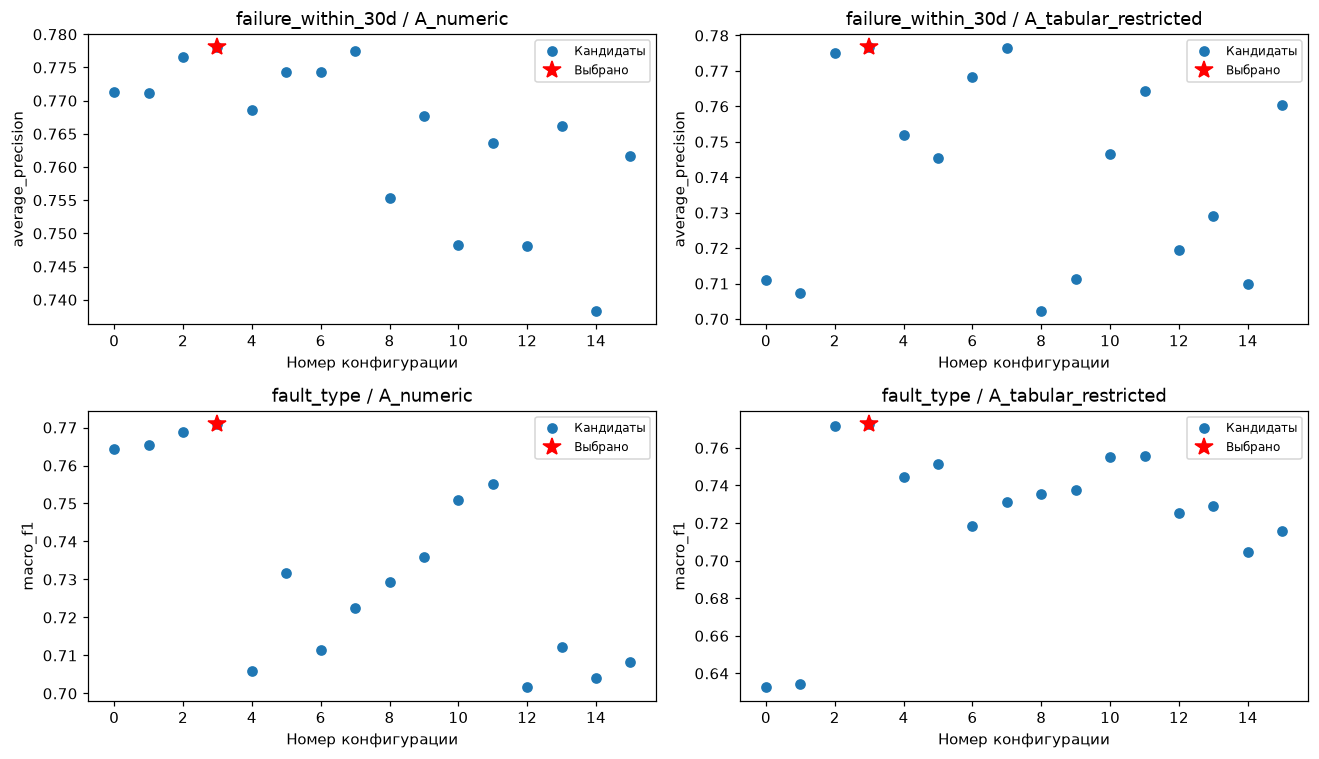

In [10]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7))
for axis, row in zip(axes.flat, selected.to_dict("records")):
    part = search_results.loc[
        search_results["target"].eq(row["target"])
        & search_results["variant"].eq(row["variant"])
    ]
    metric = f"validation_{row['selection_metric']}"
    axis.plot(part["candidate_order"], part[metric], "o", label="Кандидаты")
    axis.plot(
        row["candidate_order"],
        row[metric],
        "r*",
        markersize=12,
        label="Выбрано",
    )
    axis.set(
        xlabel="Номер конфигурации",
        ylabel=row["selection_metric"],
        title=f"{row['target']} / {row['variant']}",
    )
    axis.legend(fontsize=8)
figure.tight_layout()
batch_figures = batch_directory / "figures"
batch_figures.mkdir(exist_ok=True)
figure.savefig(batch_figures / "validation_search.png")
plt.show()
plt.close(figure)

## 7. Диагностика при исходном пороге 0,5

Проверяем загруженные модели, классы и id. Сохраняем отчёты, матрицы
ошибок, важность признаков, примеры ошибок и подгруппы equipment/severity.
severity используется для диагностики, не как вход.
Встроенная важность не доказывает причинного влияния.

### failure_within_30d / A_numeric

,precision,recall,f1-score,support
0,0.913820,0.950273,0.931690,1830.000000
1,0.686207,0.548209,0.609495,363.000000
accuracy,0.883721,0.883721,0.883721,0.883721
macro avg,0.800014,0.749241,0.770592,2193.000000
weighted avg,0.876144,0.883721,0.878358,2193.000000


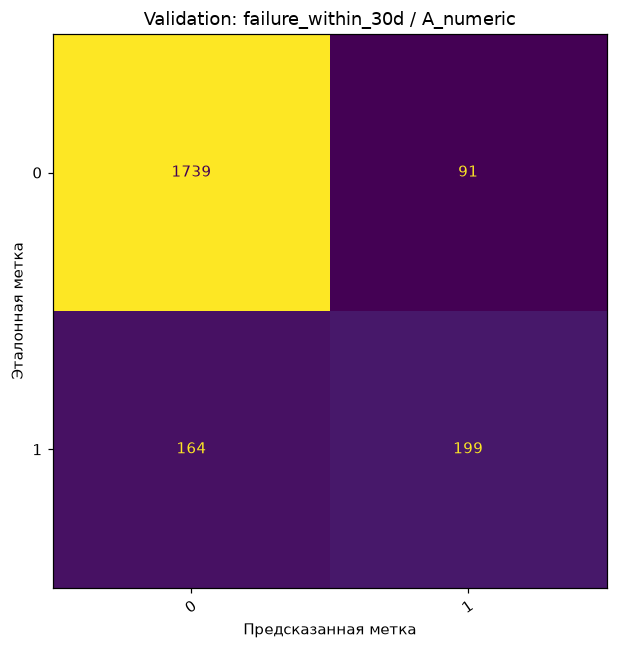

,feature,importance
3,numeric__pressure_bar,0.347871
2,numeric__vibration_mm_s,0.237652
1,numeric__temperature_c,0.216047
0,numeric__operating_hours,0.171224
4,numeric__load_ratio,0.027207


Ошибок validation: **255**.

,id,y_true,y_pred,probability_0,probability_1,predicted_probability,operator_log,equipment,severity
0,1096,1,0,0.974353,0.025647,0.974353,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
1,6283,1,0,0.964181,0.035819,0.964181,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
2,14149,1,0,0.955429,0.044571,0.955429,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium
3,13228,1,0,0.946395,0.053605,0.946395,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
4,85,0,1,0.072685,0.927315,0.927315,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
5,4792,1,0,0.926183,0.073817,0.926183,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
6,335,1,0,0.915920,0.084080,0.915920,Зафиксирован устойчивый рост температуры корпу...,PN-300,medium
7,3622,1,0,0.915388,0.084612,0.915388,После выхода на режим появилась повышенная виб...,PN-300,medium
8,13050,1,0,0.909306,0.090694,0.909306,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
9,11291,1,0,0.894523,0.105477,0.894523,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium


### failure_within_30d / A_tabular_restricted

,precision,recall,f1-score,support
0,0.913295,0.949727,0.931155,1830.000000
1,0.682759,0.545455,0.606432,363.000000
accuracy,0.882809,0.882809,0.882809,0.882809
macro avg,0.798027,0.747591,0.768793,2193.000000
weighted avg,0.875135,0.882809,0.877404,2193.000000


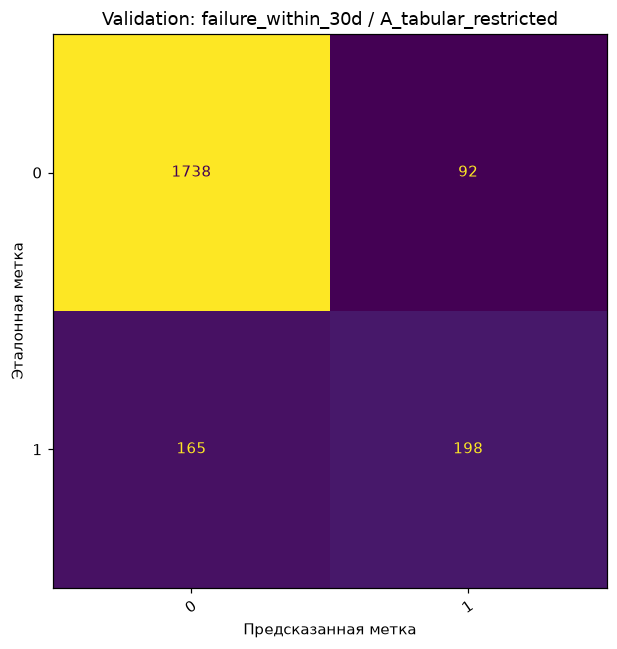

,feature,importance
3,numeric__pressure_bar,0.341059
2,numeric__vibration_mm_s,0.231164
1,numeric__temperature_c,0.209513
0,numeric__operating_hours,0.165470
4,numeric__load_ratio,0.023856
5,numeric__horizon_days,0.020118
9,categorical__equipment_PN-200,0.001575
11,categorical__equipment_TR-90,0.001401
7,categorical__equipment_CP-500,0.001184
6,categorical__equipment_CM-110,0.001164


Ошибок validation: **257**.

,id,y_true,y_pred,probability_0,probability_1,predicted_probability,operator_log,equipment,severity
0,1096,1,0,0.974588,0.025412,0.974588,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
1,6283,1,0,0.964375,0.035625,0.964375,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
2,14149,1,0,0.954660,0.045340,0.954660,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium
3,13228,1,0,0.946388,0.053612,0.946388,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
4,85,0,1,0.062168,0.937832,0.937832,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
5,4792,1,0,0.924802,0.075198,0.924802,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
6,3622,1,0,0.922269,0.077731,0.922269,После выхода на режим появилась повышенная виб...,PN-300,medium
7,3688,0,1,0.079083,0.920917,0.920917,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
8,335,1,0,0.911302,0.088698,0.911302,Зафиксирован устойчивый рост температуры корпу...,PN-300,medium
9,13050,1,0,0.910306,0.089694,0.910306,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium


### fault_type / A_numeric

,precision,recall,f1-score,support
bearing_wear,0.774775,0.674510,0.721174,255.000000
cavitation,0.847534,0.851351,0.849438,222.000000
imbalance,0.615385,0.689655,0.650407,232.000000
normal,0.886608,0.902488,0.894477,1005.000000
overheat,0.955823,0.944444,0.950100,252.000000
seal_leak,0.574074,0.546256,0.559819,227.000000
accuracy,0.816233,0.816233,0.816233,0.816233
macro avg,0.775700,0.768117,0.770903,2193.000000
weighted avg,0.816558,0.816233,0.815697,2193.000000


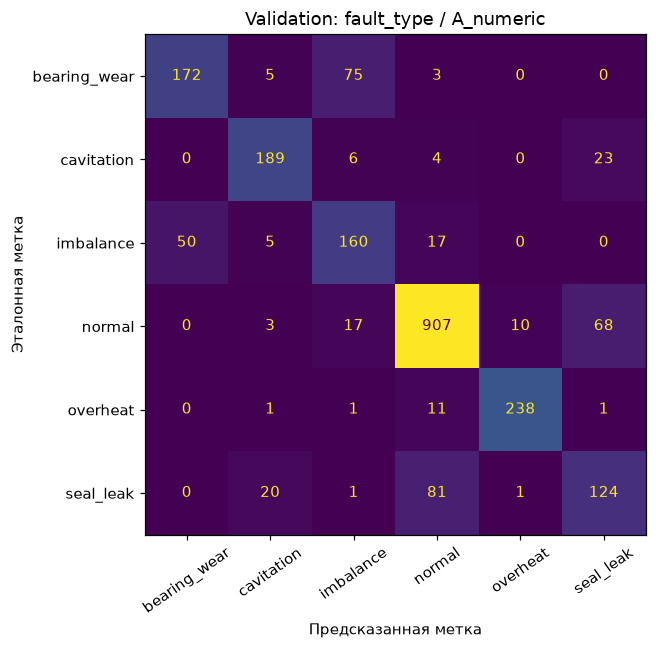

,feature,importance
2,numeric__vibration_mm_s,0.371894
3,numeric__pressure_bar,0.311873
1,numeric__temperature_c,0.272112
0,numeric__operating_hours,0.030147
4,numeric__load_ratio,0.013974


Ошибок validation: **403**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,predicted_probability,operator_log,equipment,severity
0,298,normal,overheat,0.000000,0.000000,0.000000,0.005147,0.994853,0.000000,0.994853,"Работа оборудования стабильна, посторонних шум...",PN-300,low
1,3953,imbalance,cavitation,0.001061,0.987183,0.005992,0.000043,0.000000,0.005722,0.987183,После выхода на режим появилась повышенная виб...,PN-200,medium
2,5241,normal,cavitation,0.007802,0.981656,0.007228,0.000207,0.000000,0.003106,0.981656,"Работа оборудования стабильна, посторонних шум...",CP-500,low
3,13696,seal_leak,normal,0.000389,0.000000,0.004481,0.976220,0.002778,0.016132,0.976220,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,low
4,2180,seal_leak,normal,0.000389,0.000000,0.004486,0.976133,0.002765,0.016227,0.976133,Обнаружены следы утечки в зоне уплотнения и сн...,CM-110,low
5,14740,seal_leak,normal,0.000394,0.000000,0.007287,0.973615,0.002702,0.016002,0.973615,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
6,1072,seal_leak,normal,0.000390,0.000000,0.007385,0.973543,0.002715,0.015966,0.973543,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,low
7,3144,overheat,normal,0.000518,0.000000,0.004458,0.972309,0.006318,0.016396,0.972309,Зафиксирован устойчивый рост температуры корпу...,FV-40,low
8,11327,seal_leak,normal,0.000389,0.000000,0.006650,0.972286,0.003242,0.017433,0.972286,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
9,3070,seal_leak,normal,0.000527,0.000000,0.004459,0.970933,0.007745,0.016336,0.970933,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low


### fault_type / A_tabular_restricted

,precision,recall,f1-score,support
bearing_wear,0.778281,0.674510,0.722689,255.000000
cavitation,0.854545,0.846847,0.850679,222.000000
imbalance,0.616858,0.693966,0.653144,232.000000
normal,0.887586,0.903483,0.895464,1005.000000
overheat,0.956000,0.948413,0.952191,252.000000
seal_leak,0.573394,0.550661,0.561798,227.000000
accuracy,0.817601,0.817601,0.817601,0.817601
macro avg,0.777777,0.769646,0.772661,2193.000000
weighted avg,0.818230,0.817601,0.817185,2193.000000


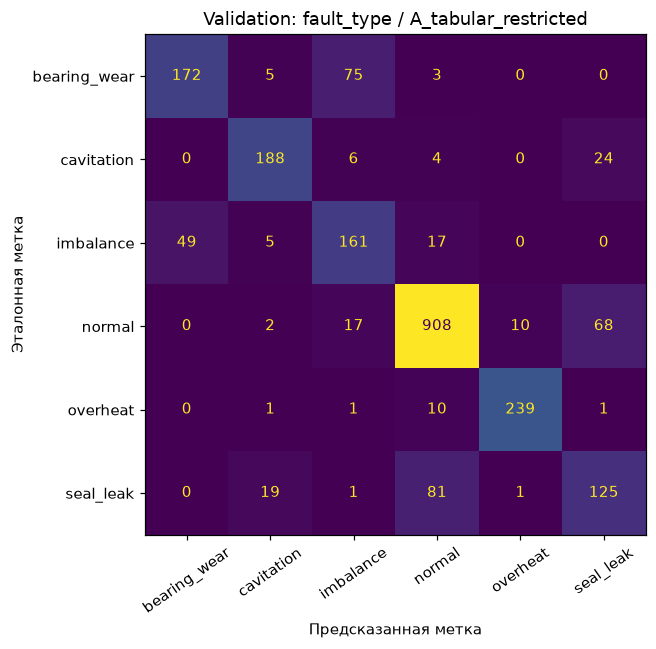

,feature,importance
2,numeric__vibration_mm_s,0.369701
3,numeric__pressure_bar,0.309948
1,numeric__temperature_c,0.270548
0,numeric__operating_hours,0.028847
4,numeric__load_ratio,0.012047
5,numeric__horizon_days,0.003952
10,categorical__equipment_PN-300,0.000710
11,categorical__equipment_TR-90,0.000548
8,categorical__equipment_FV-40,0.000508
6,categorical__equipment_CM-110,0.000369


Ошибок validation: **400**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,predicted_probability,operator_log,equipment,severity
0,3953,imbalance,cavitation,0.000280,0.994344,0.001908,0.000032,0.000000,0.003436,0.994344,После выхода на режим появилась повышенная виб...,PN-200,medium
1,298,normal,overheat,0.000000,0.000000,0.000000,0.007198,0.992802,0.000000,0.992802,"Работа оборудования стабильна, посторонних шум...",PN-300,low
2,5241,normal,cavitation,0.003111,0.984769,0.008751,0.000417,0.000000,0.002952,0.984769,"Работа оборудования стабильна, посторонних шум...",CP-500,low
3,2180,seal_leak,normal,0.000406,0.000000,0.004668,0.975741,0.003217,0.015968,0.975741,Обнаружены следы утечки в зоне уплотнения и сн...,CM-110,low
4,1072,seal_leak,normal,0.000406,0.000000,0.005676,0.974784,0.003206,0.015928,0.974784,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,low
5,14740,seal_leak,normal,0.000398,0.000000,0.005668,0.974166,0.003200,0.016568,0.974166,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
6,13696,seal_leak,normal,0.000403,0.000000,0.004605,0.974085,0.003163,0.017743,0.974085,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,low
7,3144,overheat,normal,0.000493,0.000000,0.004662,0.974061,0.004747,0.016038,0.974061,Зафиксирован устойчивый рост температуры корпу...,FV-40,low
8,11327,seal_leak,normal,0.000404,0.000002,0.005905,0.973214,0.003547,0.016928,0.973214,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
9,3070,seal_leak,normal,0.000474,0.000000,0.008095,0.968153,0.007663,0.015615,0.968153,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low


Важность признаков описывает модель, не причинное влияние. Старые запуски и их записи MLflow не изменяются.

In [11]:
selected_predictions = {}
diagnostic_root = batch_directory / "diagnostics"
for row in diagnostic_records.to_dict("records"):
    run_directory = PROJECT_ROOT / row["run_path"]
    diagnostic_directory = diagnostic_root / row["run_id"]
    diagnostic_directory.mkdir(parents=True, exist_ok=True)
    with (run_directory / "model.pkl").open("rb") as model_file:
        restored_pipeline = pickle.load(model_file)
    classes = restored_pipeline.classes_.tolist()
    run_manifest = json.loads(
        (run_directory / "manifest.json").read_text(encoding="utf-8")
    )
    features = run_manifest["features"]
    inputs = validation[features]
    predictions = pd.read_csv(
        run_directory / "validation_predictions.csv", dtype={"id": "string"}
    )
    assert predictions["id"].tolist() == validation["id"].tolist()
    probability_columns = [f"probability_{label}" for label in classes]
    np.testing.assert_allclose(
        restored_pipeline.predict_proba(inputs),
        predictions[probability_columns],
        atol=1e-12,
        rtol=1e-12,
    )
    selected_predictions[(row["target"], row["variant"])] = predictions
    report = pd.DataFrame(
        classification_report(
            predictions["y_true"],
            predictions["y_pred"],
            labels=classes,
            target_names=[str(label) for label in classes],
            output_dict=True,
            zero_division=0,
        )
    ).T
    report.to_csv(diagnostic_directory / "classification_report.csv")
    display(Markdown(f"### {row['target']} / {row['variant']}"))
    display(report)
    figure, axis = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        predictions["y_true"],
        predictions["y_pred"],
        labels=classes,
        ax=axis,
        colorbar=False,
        xticks_rotation=35,
    )
    axis.set_xlabel("Предсказанная метка")
    axis.set_ylabel("Эталонная метка")
    axis.set_title(f"Validation: {row['target']} / {row['variant']}")
    figure.tight_layout()
    figure.savefig(diagnostic_directory / "confusion_matrix.png")
    plt.show()
    plt.close(figure)
    if CONFIG["family"] == "random_forest":
        preprocessing = restored_pipeline.named_steps["preprocessing"]
        feature_names = preprocessing.get_feature_names_out()
        importance = restored_pipeline.named_steps[
            "classifier"
        ].feature_importances_
    else:
        feature_names = restored_pipeline.feature_names_
        importance = restored_pipeline.feature_importances_
    importance_table = pd.DataFrame(
        {"feature": feature_names, "importance": importance}
    )
    importance_table = importance_table.sort_values(
        "importance", ascending=False
    )
    importance_table.to_csv(
        diagnostic_directory / "feature_importance.csv", index=False
    )
    display(importance_table.head(20))
    errors = predictions.loc[
        predictions["y_true"].ne(predictions["y_pred"])
    ].copy()
    errors["predicted_probability"] = errors[probability_columns].max(axis=1)
    errors = errors.sort_values("predicted_probability", ascending=False)
    errors = errors.merge(
        validation[["id", "operator_log", "equipment", "severity"]],
        on="id",
        validate="one_to_one",
    )
    errors.head(CONFIG["error_examples"]).to_csv(
        diagnostic_directory / "error_examples.csv", index=False
    )
    display(Markdown(f"Ошибок validation: **{len(errors)}**."))
    if not errors.empty:
        display(errors.head(CONFIG["error_examples"]))
    subgroup_source = predictions.merge(
        validation[["id", "equipment", "severity"]],
        on="id",
        validate="one_to_one",
    )
    subgroup_records = []
    for grouping in ["equipment", "severity"]:
        for value, part in subgroup_source.groupby(grouping):
            subgroup_records.append(
                {
                    "grouping": grouping,
                    "value": value,
                    "records": len(part),
                    **baseline.classification_metrics(
                        part, classes, row["target"]
                    ),
                }
            )
    pd.DataFrame(subgroup_records).to_csv(
        diagnostic_directory / "subgroups.csv", index=False
    )
    if run_directory.parent.parent == batch_directory:
        mlflow.log_artifacts(
            str(diagnostic_directory),
            artifact_path="validation_diagnostics",
            run_id=row["run_id"],
        )
display(
    Markdown(
        "Важность признаков описывает модель, не причинное влияние. "
        "Старые запуски и их записи MLflow не изменяются."
    )
)

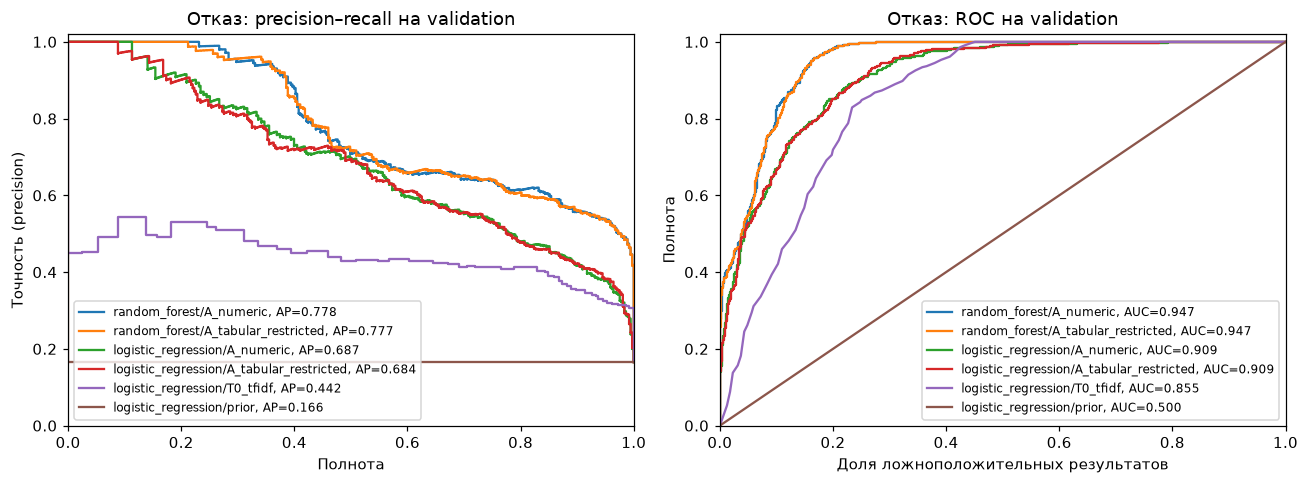

In [12]:
batch_figures = batch_directory / "figures"
batch_figures.mkdir(exist_ok=True)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
binary_target = "failure_within_30d"
for row in comparison.loc[comparison["target"].eq(binary_target)].to_dict(
    "records"
):
    predictions = pd.read_csv(
        PROJECT_ROOT / row["run_path"] / "validation_predictions.csv"
    )
    truth = predictions["y_true"]
    probabilities = predictions["probability_1"]
    precision, recall, _ = precision_recall_curve(truth, probabilities)
    false_positive_rate, true_positive_rate, _ = roc_curve(
        truth, probabilities
    )
    metrics = baseline.classification_metrics(
        predictions, [0, 1], binary_target
    )
    axes[0].step(
        recall,
        precision,
        where="post",
        label=(
            f"{row['family']}/{row['variant']}, "
            f"AP={metrics['average_precision']:.3f}"
        ),
    )
    axes[1].plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{row['family']}/{row['variant']}, AUC={metrics['roc_auc']:.3f}"
        ),
    )
axes[0].set_title("Отказ: precision–recall на validation")
axes[0].set_xlabel("Полнота")
axes[0].set_ylabel("Точность (precision)")
axes[1].set_title("Отказ: ROC на validation")
axes[1].set_xlabel("Доля ложноположительных результатов")
axes[1].set_ylabel("Полнота")
for axis in axes:
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1.02)
    axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(batch_figures / "failure_validation_curves.png")
plt.show()
plt.close(figure)

## 8. Порог отказа по validation F2

Для двух моделей, уже выбранных по AP, этой семьи перебираем
уникальные вероятности плюс 0, 0,5 и 1. Отказ: `probability_1 >= threshold`.
Максимизируем F2; равенство до 12 знаков разрешаем по большей precision,
затем большему порогу. При отсутствии обоих классов расчёт завершается
ошибкой. Порог не выбирает конфигурацию и не меняет вероятности.

Сохраняем перебор, сравнение с 0,5, прогнозы train/validation, матрицы ошибок
и `model_f2.pkl`: `FixedThresholdClassifier` поверх готовой модели,
**без fit и без train+validation**. Исходный `model.pkl` сохраняется.
Параметры и результаты дописываются в те же записи MLflow; новых записей нет.

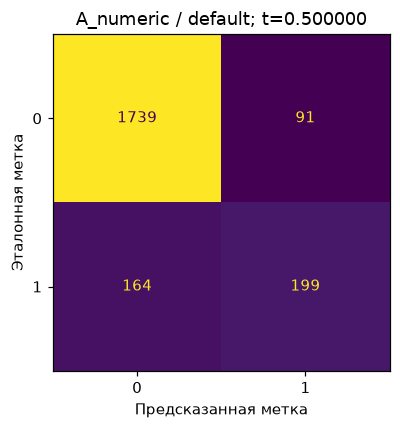

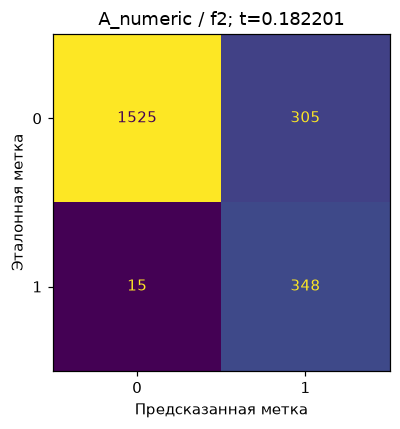

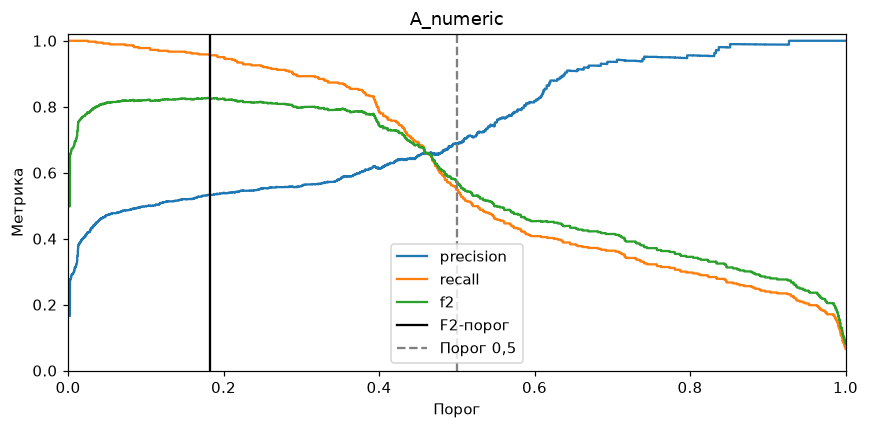

2026-10-17 23:36:12,933 INFO F2-порог A_numeric: 0.18220070093700882; F2 0.571183 -> 0.826603


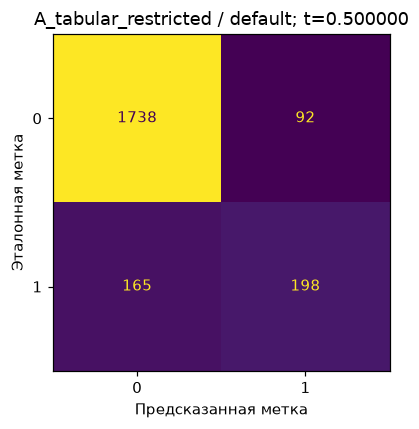

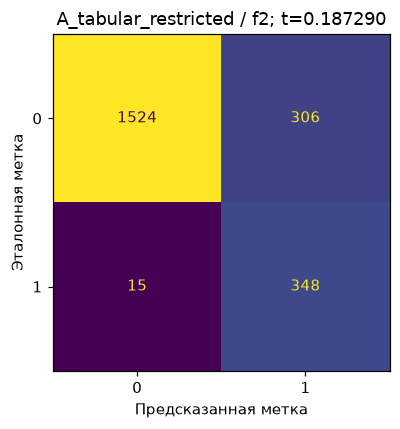

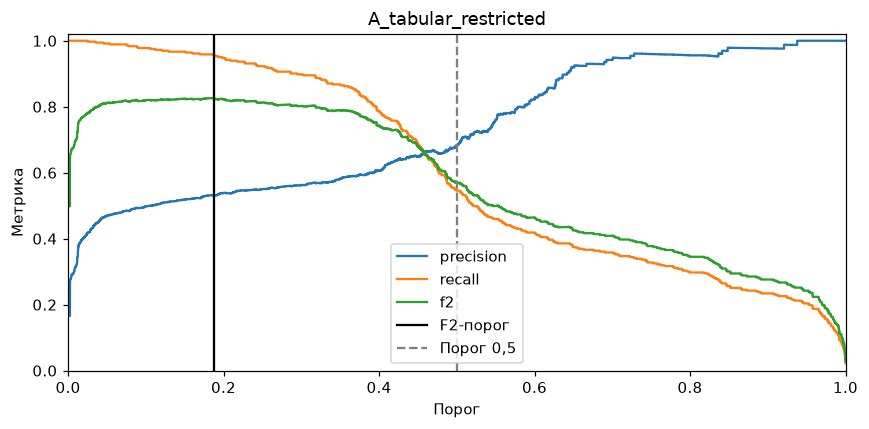

2026-10-17 23:36:14,086 INFO F2-порог A_tabular_restricted: 0.1872898061910771; F2 0.568312 -> 0.826211


,run_id,run_path,variant,default_threshold,selected_threshold,candidate_count,default_precision,selected_precision,delta_precision,default_recall,...,delta_tp,default_fp,selected_fp,delta_fp,default_tn,selected_tn,delta_tn,default_fn,selected_fn,delta_fn
0,6081e28363bd4d568e4ce486db5ac594,artifacts/experiments/random_forest_20261017T2...,A_numeric,0.5,0.182201,1064,0.686207,0.532925,-0.153282,0.548209,...,149,91,305,214,1739,1525,-214,164,15,-149
1,3f231364cf124ad48ea72ee222ed53e6,artifacts/experiments/random_forest_20261017T2...,A_tabular_restricted,0.5,0.187290,1103,0.682759,0.532110,-0.150649,0.545455,...,150,92,306,214,1738,1524,-214,165,15,-150


In [13]:
threshold_config = CONFIG["threshold_selection"]
assert threshold_config["beta"] == 2
assert threshold_config["selection_split"] == "validation"
assert not threshold_config["refit"]
threshold_records = []
binary_models = selected.loc[selected["target"].eq(binary_target)]
assert len(binary_models) == CONFIG["expected_threshold_models"]
for row in binary_models.to_dict("records"):
    run_directory = PROJECT_ROOT / row["run_path"]
    assert run_directory.parent.parent == batch_directory
    threshold_directory = run_directory / "threshold_selection"
    threshold_directory.mkdir(exist_ok=True)
    run_manifest = json.loads(
        (run_directory / "manifest.json").read_text(encoding="utf-8")
    )
    with (run_directory / "model.pkl").open("rb") as model_file:
        fitted_model = pickle.load(model_file)
    validation_default = pd.read_csv(
        run_directory / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    assert validation_default["id"].tolist() == validation["id"].tolist()
    np.testing.assert_array_equal(
        validation_default["y_true"], validation[binary_target]
    )
    best, threshold_curve = baseline.select_failure_threshold(
        validation_default["y_true"],
        validation_default["probability_1"],
        selection_decimals=threshold_config["selection_decimals"],
    )
    threshold_curve.to_csv(
        threshold_directory / "threshold_search.csv", index=False
    )
    default_counts = threshold_curve.loc[
        threshold_curve["threshold"].eq(CONFIG["binary_threshold"])
    ].iloc[0]
    threshold_record = {
        "run_id": row["run_id"],
        "run_path": row["run_path"],
        "variant": row["variant"],
        "default_threshold": CONFIG["binary_threshold"],
        "selected_threshold": best["threshold"],
        "candidate_count": len(threshold_curve),
    }
    wrapper = FixedThresholdClassifier(
        estimator=fitted_model,
        threshold=best["threshold"],
        pos_label=threshold_config["positive_class"],
        response_method="predict_proba",
    )
    with (run_directory / "model_f2.pkl").open("wb") as model_file:
        pickle.dump(wrapper, model_file, protocol=pickle.HIGHEST_PROTOCOL)
    with (run_directory / "model_f2.pkl").open("rb") as model_file:
        restored_wrapper = pickle.load(model_file)
    threshold_metrics = {}
    for partition, sample in [("train", train), ("validation", validation)]:
        default_predictions = pd.read_csv(
            run_directory / f"{partition}_predictions.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
        inputs = (
            sample["operator_log"]
            if row["variant"] == "T0_tfidf"
            else sample[run_manifest["features"]]
        )
        classes = fitted_model.classes_.tolist()
        probability_columns = [f"probability_{label}" for label in classes]
        probabilities = restored_wrapper.predict_proba(inputs)
        np.testing.assert_array_equal(
            probabilities, fitted_model.predict_proba(inputs)
        )
        np.testing.assert_array_equal(
            probabilities, default_predictions[probability_columns].to_numpy()
        )
        assert default_predictions["id"].tolist() == sample["id"].tolist()
        tuned_predictions = baseline.prediction_table(
            sample["id"],
            sample[binary_target],
            probabilities,
            classes,
            binary_target,
            best["threshold"],
        )
        np.testing.assert_array_equal(
            restored_wrapper.predict(inputs), tuned_predictions["y_pred"]
        )
        tuned_predictions.to_csv(
            run_directory / f"{partition}_predictions_f2.csv", index=False
        )
        old_metrics = baseline.classification_metrics(
            default_predictions, classes, binary_target
        )
        new_metrics = baseline.classification_metrics(
            tuned_predictions, classes, binary_target
        )
        for metric in ["average_precision", "roc_auc", "log_loss"]:
            assert old_metrics[metric] == new_metrics[metric]
        threshold_metrics[partition] = {
            "default": old_metrics,
            "selected": new_metrics,
        }
        if partition == "validation":
            for metric in [
                "precision",
                "recall",
                "f1",
                "f2",
                "average_precision",
                "roc_auc",
            ]:
                threshold_record[f"default_{metric}"] = old_metrics[metric]
                threshold_record[f"selected_{metric}"] = new_metrics[metric]
                threshold_record[f"delta_{metric}"] = (
                    new_metrics[metric] - old_metrics[metric]
                )
            for count in ["tp", "fp", "tn", "fn"]:
                threshold_record[f"default_{count}"] = int(
                    default_counts[count]
                )
                threshold_record[f"selected_{count}"] = best[count]
                threshold_record[f"delta_{count}"] = best[count] - int(
                    default_counts[count]
                )
            report = pd.DataFrame(
                classification_report(
                    tuned_predictions["y_true"],
                    tuned_predictions["y_pred"],
                    labels=classes,
                    output_dict=True,
                    zero_division=0,
                )
            ).T
            report.to_csv(threshold_directory / "classification_report_f2.csv")
    for name, counts in [("default", default_counts), ("f2", best)]:
        matrix = np.array(
            [[counts["tn"], counts["fp"]], [counts["fn"], counts["tp"]]],
            dtype=int,
        )
        pd.DataFrame(matrix, index=[0, 1], columns=[0, 1]).to_csv(
            threshold_directory / f"confusion_matrix_{name}.csv"
        )
        figure, axis = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(
            ax=axis, colorbar=False
        )
        axis.set_xlabel("Предсказанная метка")
        axis.set_ylabel("Эталонная метка")
        axis.set_title(
            f"{row['variant']} / {name}; t={counts['threshold']:.6f}"
        )
        figure.tight_layout()
        figure.savefig(threshold_directory / f"confusion_matrix_{name}.png")
        plt.show()
        plt.close(figure)
    figure, axis = plt.subplots(figsize=(8, 4))
    for metric in ["precision", "recall", "f2"]:
        axis.step(
            threshold_curve["threshold"],
            threshold_curve[metric],
            where="pre",
            label=metric,
        )
    axis.axvline(best["threshold"], label="F2-порог", color="black")
    axis.axvline(
        CONFIG["binary_threshold"],
        label="Порог 0,5",
        color="grey",
        linestyle="--",
    )
    axis.set(
        xlabel="Порог",
        ylabel="Метрика",
        title=row["variant"],
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axis.legend()
    figure.tight_layout()
    figure.savefig(threshold_directory / "threshold_curve.png")
    plt.show()
    plt.close(figure)
    threshold_manifest = {
        **threshold_record,
        "selection": threshold_config,
        "metrics": threshold_metrics,
        "best_counts": best,
        "fitted_again": False,
        "limitation": "Конфигурация и порог выбраны на одной validation; "
        "оценки и интервалы могут быть оптимистичными.",
    }
    (threshold_directory / "manifest.json").write_text(
        json.dumps(threshold_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    run_manifest["threshold_selection"] = threshold_manifest
    (run_directory / "manifest.json").write_text(
        json.dumps(run_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    with mlflow.start_run(run_id=row["run_id"]):
        mlflow.log_params(
            {
                "f2_threshold": best["threshold"],
                "threshold_selection_metric": "f2",
                "threshold_selection_split": "validation",
                "threshold_refit": False,
            }
        )
        mlflow.log_metrics(
            {
                f"{partition}_{metric}_at_f2_threshold": value
                for partition, scores in threshold_metrics.items()
                for metric, value in scores["selected"].items()
                if value is not None
            }
        )
        mlflow.log_metrics(
            {
                f"validation_{name}": float(value)
                for name, value in threshold_record.items()
                if name.startswith(("delta_", "selected_"))
            }
        )
        mlflow.log_artifact(str(run_directory / "model_f2.pkl"))
        for partition in ["train", "validation"]:
            mlflow.log_artifact(
                str(run_directory / f"{partition}_predictions_f2.csv")
            )
        mlflow.log_artifact(str(run_directory / "manifest.json"))
        mlflow.log_artifacts(
            str(threshold_directory), artifact_path="threshold_selection"
        )
    logger.info(
        "F2-порог %s: %.17g; F2 %.6f -> %.6f",
        row["variant"],
        best["threshold"],
        threshold_record["default_f2"],
        threshold_record["selected_f2"],
    )
    threshold_records.append(threshold_record)
    pd.DataFrame(threshold_records).to_csv(
        batch_directory / "threshold_comparison.csv", index=False
    )
threshold_results = pd.DataFrame(threshold_records)
display(threshold_results)

## 9. Полнота при precision ≥ 70% и ≥ 80%

Диагностические точки не заменяют рабочий F2-порог. При недостижимом
ограничении сохраняется статус unattainable с пустыми метриками.
Исключаем решения без положительных прогнозов. Равенство полноты
до 12 знаков разрешается по большей precision, затем большему порогу.
Для прежних моделей читаем прогнозы без изменения их файлов.

In [14]:
operating_records = []
for row in comparison.loc[comparison["target"].eq(binary_target)].to_dict(
    "records"
):
    model_directory = PROJECT_ROOT / row["run_path"]
    predictions = pd.read_csv(
        model_directory / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    _, curve = baseline.select_failure_threshold(
        predictions["y_true"],
        predictions["probability_1"],
        CONFIG["selection_decimals"],
    )
    model_points = []
    for floor in CONFIG["precision_floors"]:
        point = baseline.precision_recall_operating_point(
            curve, floor, CONFIG["selection_decimals"]
        )
        record = {
            "family": row["family"],
            "variant": row["variant"],
            "run_id": row["run_id"],
            **point,
        }
        operating_records.append(record)
        model_points.append(record)
    if row["run_id"] in set(selected["run_id"]):
        path = (
            model_directory
            / "threshold_selection"
            / "precision_operating_points.csv"
        )
        pd.DataFrame(model_points).to_csv(path, index=False)
        mlflow.log_artifact(
            str(path),
            artifact_path="threshold_selection",
            run_id=row["run_id"],
        )
precision_results = pd.DataFrame(operating_records)
precision_results.to_csv(
    batch_directory / "precision_operating_points.csv", index=False
)
display(precision_results)

,family,variant,run_id,precision_floor,status,threshold,precision,recall,f1,f2,tp,fp,tn,fn
0,random_forest,A_numeric,6081e28363bd4d568e4ce486db5ac594,0.7,attainable,0.510510,0.705224,0.520661,0.599049,0.549419,189.0,79.0,1751.0,174.0
1,random_forest,A_numeric,6081e28363bd4d568e4ce486db5ac594,0.8,attainable,0.587071,0.805263,0.421488,0.553345,0.465895,153.0,37.0,1793.0,210.0
2,random_forest,A_tabular_restricted,3f231364cf124ad48ea72ee222ed53e6,0.7,attainable,0.506414,0.700000,0.539945,0.609642,0.565820,196.0,84.0,1746.0,167.0
3,random_forest,A_tabular_restricted,3f231364cf124ad48ea72ee222ed53e6,0.8,attainable,0.582993,0.800000,0.429752,0.559140,0.473588,156.0,39.0,1791.0,207.0
4,logistic_regression,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f,0.7,attainable,0.324783,0.701550,0.498623,0.582931,0.529240,181.0,77.0,1753.0,182.0
5,logistic_regression,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f,0.8,attainable,0.379855,0.800000,0.341598,0.478764,0.385812,124.0,31.0,1799.0,239.0
6,logistic_regression,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542,0.7,attainable,0.327773,0.712000,0.490358,0.580750,0.522914,178.0,72.0,1758.0,185.0
7,logistic_regression,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542,0.8,attainable,0.386715,0.800000,0.319559,0.456693,0.363181,116.0,29.0,1801.0,247.0
8,logistic_regression,T0_tfidf,c0256cbf1a754a7d970c974b7923e481,0.7,unattainable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,logistic_regression,T0_tfidf,c0256cbf1a754a7d970c974b7923e481,0.8,unattainable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Парные сравнения AP и macro-F1

Для каждой выбранной модели: соответствующая табличная логистическая
регрессия, текстовый контроль и prior. В CatBoost дополнительно
сравниваем соответствующий Random Forest. Парный групповой бутстрэп:
2 000 повторов, seed 42, одни id, целые group_id.

In [15]:
comparison_pairs = []
for candidate in selected.to_dict("records"):
    same_target = reference_models.loc[
        reference_models["target"].eq(candidate["target"])
    ]
    baseline_references = same_target.loc[
        same_target["family"].eq("logistic_regression")
        & same_target["variant"].isin(
            [candidate["variant"], "T0_tfidf", "prior"]
        )
    ]
    assert len(baseline_references) == 3
    for reference in baseline_references.to_dict("records"):
        comparison_pairs.append(("vs_logistic_or_prior", reference, candidate))
    if CONFIG["family"] == "catboost":
        forest = (
            same_target.loc[
                same_target["family"].eq("random_forest")
                & same_target["variant"].eq(candidate["variant"])
            ]
            .iloc[0]
            .to_dict()
        )
        comparison_pairs.append(("catboost_vs_forest", forest, candidate))
validation_membership = membership.loc[
    membership["split"].eq("validation"), ["id", "group_id"]
]
bootstrap_records = []
for kind, reference, candidate in comparison_pairs:
    target = candidate["target"]
    logger.info(
        "Парное сравнение %s: %s/%s против %s/%s",
        target,
        candidate["family"],
        candidate["variant"],
        reference["family"],
        reference["variant"],
    )
    reference_predictions = pd.read_csv(
        PROJECT_ROOT / reference["run_path"] / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    candidate_predictions = pd.read_csv(
        PROJECT_ROOT / candidate["run_path"] / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    result = comparison_tools.paired_group_bootstrap(
        reference_predictions,
        candidate_predictions,
        validation_membership,
        sorted(train[target].unique().tolist()),
        target,
        **CONFIG["bootstrap"],
    )
    bootstrap_records.append(
        {
            "kind": kind,
            "target": target,
            "reference_family": reference["family"],
            "reference_variant": reference["variant"],
            "candidate_family": candidate["family"],
            "candidate_variant": candidate["variant"],
            "reference_run_id": reference["run_id"],
            "candidate_run_id": candidate["run_id"],
            **result,
        }
    )
    pd.DataFrame(bootstrap_records).to_csv(
        batch_directory / "paired_bootstrap.csv", index=False
    )
bootstrap_results = pd.DataFrame(bootstrap_records)
assert len(bootstrap_results) == CONFIG["expected_primary_comparisons"]
display(bootstrap_results)

2026-10-17 23:36:14,236 INFO Парное сравнение failure_within_30d: random_forest/A_numeric против logistic_regression/A_numeric


2026-10-17 23:36:17,060 INFO Парное сравнение failure_within_30d: random_forest/A_numeric против logistic_regression/T0_tfidf


2026-10-17 23:36:19,214 INFO Парное сравнение failure_within_30d: random_forest/A_numeric против logistic_regression/prior


2026-10-17 23:36:21,271 INFO Парное сравнение failure_within_30d: random_forest/A_tabular_restricted против logistic_regression/A_tabular_restricted


2026-10-17 23:36:23,548 INFO Парное сравнение failure_within_30d: random_forest/A_tabular_restricted против logistic_regression/T0_tfidf


...

2026-10-17 23:36:54,349 INFO Парное сравнение fault_type: random_forest/A_numeric против logistic_regression/prior


2026-10-17 23:37:07,707 INFO Парное сравнение fault_type: random_forest/A_tabular_restricted против logistic_regression/A_tabular_restricted


2026-10-17 23:37:20,946 INFO Парное сравнение fault_type: random_forest/A_tabular_restricted против logistic_regression/T0_tfidf


2026-10-17 23:37:34,088 INFO Парное сравнение fault_type: random_forest/A_tabular_restricted против logistic_regression/prior


,kind,target,reference_family,reference_variant,candidate_family,candidate_variant,reference_run_id,candidate_run_id,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,seed,direction
0,vs_logistic_or_prior,failure_within_30d,logistic_regression,A_numeric,random_forest,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f,6081e28363bd4d568e4ce486db5ac594,average_precision,0.687009,0.778035,0.091027,0.055762,0.127923,59,2000,2000,0,42,candidate - reference
1,vs_logistic_or_prior,failure_within_30d,logistic_regression,T0_tfidf,random_forest,A_numeric,c0256cbf1a754a7d970c974b7923e481,6081e28363bd4d568e4ce486db5ac594,average_precision,0.442193,0.778035,0.335842,0.289245,0.381619,59,2000,2000,0,42,candidate - reference
2,vs_logistic_or_prior,failure_within_30d,logistic_regression,prior,random_forest,A_numeric,c2abf8dc3897473ab466615e5a546fb6,6081e28363bd4d568e4ce486db5ac594,average_precision,0.165527,0.778035,0.612509,0.544125,0.673473,59,2000,2000,0,42,candidate - reference
3,vs_logistic_or_prior,failure_within_30d,logistic_regression,A_tabular_restricted,random_forest,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542,3f231364cf124ad48ea72ee222ed53e6,average_precision,0.683601,0.776655,0.093055,0.057832,0.129879,59,2000,2000,0,42,candidate - reference
4,vs_logistic_or_prior,failure_within_30d,logistic_regression,T0_tfidf,random_forest,A_tabular_restricted,c0256cbf1a754a7d970c974b7923e481,3f231364cf124ad48ea72ee222ed53e6,average_precision,0.442193,0.776655,0.334462,0.287897,0.380985,59,2000,2000,0,42,candidate - reference
5,vs_logistic_or_prior,failure_within_30d,logistic_regression,prior,random_forest,A_tabular_restricted,c2abf8dc3897473ab466615e5a546fb6,3f231364cf124ad48ea72ee222ed53e6,average_precision,0.165527,0.776655,0.611129,0.540123,0.671862,59,2000,2000,0,42,candidate - reference
6,vs_logistic_or_prior,fault_type,logistic_regression,A_numeric,random_forest,A_numeric,c7a03ae5a8f142c3bb1fb392f0506fac,d08df3e322804da3b83bfb7059896b0e,macro_f1,0.770368,0.770903,0.000535,-0.018682,0.020765,59,2000,2000,0,42,candidate - reference
7,vs_logistic_or_prior,fault_type,logistic_regression,T0_tfidf,random_forest,A_numeric,a524dbade83044728f1394cc1049ce1b,d08df3e322804da3b83bfb7059896b0e,macro_f1,1.000000,0.770903,-0.229097,-0.265872,-0.213600,59,2000,2000,0,42,candidate - reference
8,vs_logistic_or_prior,fault_type,logistic_regression,prior,random_forest,A_numeric,af0c6bda51b945378cd563fe9a46f245,d08df3e322804da3b83bfb7059896b0e,macro_f1,0.104753,0.770903,0.666150,0.613554,0.705029,59,2000,2000,0,42,candidate - reference
9,vs_logistic_or_prior,fault_type,logistic_regression,A_tabular_restricted,random_forest,A_tabular_restricted,71e68116dc904b408936c5df2ac04c71,41b88bbfca4142e48468fe70f9847ed5,macro_f1,0.766584,0.772661,0.006077,-0.011600,0.023162,59,2000,2000,0,42,candidate - reference


## 11. Парные сравнения F2

Для двух моделей отказа: F2-порог против 0,5 и против сохранённого
F2-решения соответствующей логистической регрессии. Пороги фиксированы
в 2 000 групповых повторах. F2 использует zero_division=0.
Интервалы условны относительно выбора на одной validation и могут
быть оптимистичными; итоговую тестовую оценку они не заменяют.

In [16]:
threshold_bootstrap_records = []
for candidate in threshold_results.to_dict("records"):
    model_directory = PROJECT_ROOT / candidate["run_path"]
    tuned = pd.read_csv(
        model_directory / "validation_predictions_f2.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    logistic = reference_models.loc[
        reference_models["family"].eq("logistic_regression")
        & reference_models["target"].eq(binary_target)
        & reference_models["variant"].eq(candidate["variant"])
    ].iloc[0]
    references = [
        (
            "f2_vs_half",
            model_directory / "validation_predictions.csv",
            candidate["run_id"],
        ),
        (
            "f2_vs_logistic",
            PROJECT_ROOT
            / logistic["run_path"]
            / "validation_predictions_f2.csv",
            logistic["run_id"],
        ),
    ]
    for kind, path, reference_run_id in references:
        reference = pd.read_csv(
            path, dtype={"id": "string"}, float_precision="round_trip"
        )
        logger.info("Сравнение %s: %s", kind, candidate["variant"])
        result = comparison_tools.paired_group_bootstrap(
            reference,
            tuned,
            validation_membership,
            [0, 1],
            binary_target,
            metric="f2",
            **CONFIG["bootstrap"],
        )
        threshold_bootstrap_records.append(
            {
                "kind": kind,
                "variant": candidate["variant"],
                "reference_run_id": reference_run_id,
                "candidate_run_id": candidate["run_id"],
                **result,
            }
        )
        with mlflow.start_run(run_id=candidate["run_id"]):
            mlflow.log_metrics(
                {
                    f"{kind}_{key}": result[key]
                    for key in [
                        "difference",
                        "lower_95",
                        "upper_95",
                        "valid_repeats",
                        "skipped_repeats",
                    ]
                    if result[key] is not None
                }
            )
        pd.DataFrame(threshold_bootstrap_records).to_csv(
            batch_directory / "threshold_bootstrap.csv", index=False
        )
threshold_bootstrap_results = pd.DataFrame(threshold_bootstrap_records)
assert len(threshold_bootstrap_results) == CONFIG["expected_f2_comparisons"]
display(threshold_bootstrap_results)

2026-10-17 23:37:47,233 INFO Сравнение f2_vs_half: A_numeric


2026-10-17 23:37:50,763 INFO Сравнение f2_vs_logistic: A_numeric


2026-10-17 23:37:54,373 INFO Сравнение f2_vs_half: A_tabular_restricted


2026-10-17 23:37:57,978 INFO Сравнение f2_vs_logistic: A_tabular_restricted


,kind,variant,reference_run_id,candidate_run_id,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,seed,direction
0,f2_vs_half,A_numeric,6081e28363bd4d568e4ce486db5ac594,6081e28363bd4d568e4ce486db5ac594,f2,0.571183,0.826603,0.255421,0.210425,0.310773,59,2000,2000,0,42,candidate - reference
1,f2_vs_logistic,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f,6081e28363bd4d568e4ce486db5ac594,f2,0.736098,0.826603,0.090505,0.061777,0.121539,59,2000,2000,0,42,candidate - reference
2,f2_vs_half,A_tabular_restricted,3f231364cf124ad48ea72ee222ed53e6,3f231364cf124ad48ea72ee222ed53e6,f2,0.568312,0.826211,0.257899,0.209919,0.314004,59,2000,2000,0,42,candidate - reference
3,f2_vs_logistic,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542,3f231364cf124ad48ea72ee222ed53e6,f2,0.740578,0.826211,0.085632,0.057610,0.119560,59,2000,2000,0,42,candidate - reference


## 12. Результат и сохранность

64 записи моделей, четыре выбранных классификатора, два F2-объекта.
Новых обучений и записей при подборе порога нет. Фиксируем фактические
метрики, ограничения и число пригодных повторов. Test не оценивается.

In [17]:
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
assert (
    data.file_sha256(PROJECT_ROOT / dataset_config["dataset"])
    == dataset_config["sha256"]
)
for relative, checksum in reference_checksums.items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
tracked_runs = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string=f"tags.batch_id = '{batch_id}'",
)
assert len(tracked_runs) == CONFIG["expected_new_runs"]
assert tracked_runs["status"].eq("FINISHED").all()
assert (
    len(list(batch_directory.rglob("model.pkl")))
    == CONFIG["expected_new_runs"]
)
assert (
    len(list(batch_directory.rglob("model_f2.pkl")))
    == CONFIG["expected_threshold_models"]
)
assert not list(batch_directory.rglob("*test*predictions*"))
tracked_runs.to_csv(batch_directory / "mlflow_runs.csv", index=False)
findings = [
    f"# {CONFIG['family']}: результаты validation",
    "",
    f"Группа: `{batch_id}`.",
    "",
]
for row in selected.to_dict("records"):
    path = PROJECT_ROOT / row["run_path"] / "manifest.json"
    trial = json.loads(path.read_text(encoding="utf-8"))
    search_parameters = {
        key: trial["model_parameters"][key] for key in CONFIG["search"]
    }
    parameters_text = json.dumps(search_parameters, ensure_ascii=False)
    findings.append(
        f"- `{row['target']}` / `{row['variant']}`: "
        f"{row['selection_metric']}={row['selected_validation_score']:.6f}; "
        f"параметры поиска {parameters_text}."
    )
findings.extend(["", "## Пороги F2", ""])
for row in threshold_results.to_dict("records"):
    findings.append(
        f"- `{row['variant']}`: порог {row['selected_threshold']:.17g}; "
        f"F2 {row['default_f2']:.6f} → {row['selected_f2']:.6f}; "
        f"precision {row['selected_precision']:.6f}, "
        f"recall {row['selected_recall']:.6f}; "
        f"FN {row['default_fn']} → {row['selected_fn']}, "
        f"FP {row['default_fp']} → {row['selected_fp']}."
    )
findings.extend(["", "## Полнота при ограничении precision", ""])
current_points = precision_results.loc[
    precision_results["family"].eq(CONFIG["family"])
]
for row in current_points.to_dict("records"):
    label = (
        f"- `{row['variant']}`, "
        f"минимум precision {row['precision_floor']:.0%}: "
    )
    if row["status"] == "attainable":
        findings.append(
            label + f"precision {row['precision']:.6f}, "
            f"recall {row['recall']:.6f}; порог {row['threshold']:.17g}."
        )
    else:
        findings.append(label + "недостижимо.")
findings.extend(["", "## Парные разности: candidate − reference", ""])
f2_report = threshold_bootstrap_results.assign(
    target=binary_target,
    candidate_variant=threshold_bootstrap_results["variant"],
)
all_comparisons = pd.concat([bootstrap_results, f2_report], ignore_index=True)
for row in all_comparisons.to_dict("records"):
    interval = (
        f"[{row['lower_95']:+.6f}; {row['upper_95']:+.6f}]"
        if pd.notna(row["lower_95"])
        else "не определён"
    )
    findings.append(
        f"- {row['kind']} / `{row['target']}` / "
        f"`{row['candidate_variant']}`: "
        f"Δ{row['metric']}={row['difference']:+.6f}; "
        f"95%-й интервал {interval}; "
        f"пригодных повторов {row['valid_repeats']}, "
        f"пропущено {row['skipped_repeats']}; "
        f"reference={row['reference_run_id']}, "
        f"candidate={row['candidate_run_id']}."
    )
findings.extend(
    [
        "",
        "Конфигурации, F2-пороги и диагностические точки выбраны на одной "
        "validation. Оценки и интервалы условны относительно выбора и могут "
        "быть оптимистичными; итоговую тестовую оценку они не заменяют. "
        "Пороги в бутстрэпе фиксированы. Шесть общих текстовых шаблонов "
        "ограничивают перенос текстового контроля.",
        "",
        "required_route, severity, id и обе цели исключены из входов. "
        "severity используется только в диагностике подгрупп. "
        "Test не оценивался. Нет объединения входов или прогнозов, "
        "калибровки и переобучения на train+validation.",
        "",
        "Реализация этапа выполнена агентом по согласованному плану "
        "пользователя. Фактическое авторство остальных участников "
        "требует подтверждения.",
    ]
)
summary_text = "\n".join(findings)
(batch_directory / "summary.md").write_text(summary_text, encoding="utf-8")
manifest.update(
    {
        "status": "completed",
        "new_fit_count": len(search_results),
        "fits_in_this_execution": 0 if reuse_batch else len(search_results),
        "reused_completed_fit_count": len(search_results)
        if reuse_batch
        else 0,
        "initial_parallel_archive": "initial_parallel"
        if reuse_batch
        else None,
        "selected_count": len(selected),
        "threshold_model_count": len(threshold_results),
        "threshold_refit_count": 0,
        "primary_comparison_count": len(bootstrap_results),
        "f2_comparison_count": len(threshold_bootstrap_results),
        "selected_runs": selected["run_id"].tolist(),
        "duration_seconds": perf_counter() - started_clock,
    }
)
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(Markdown(summary_text))
logger.info("Эксперимент завершён: %s", batch_directory)

# random_forest: результаты validation

Группа: `random_forest_20261017T203223_834932Z`.

- `failure_within_30d` / `A_numeric`: average_precision=0.778035; параметры поиска {"max_depth": 8, "min_samples_leaf": 5, "max_features": 1.0, "class_weight": null}.
- `failure_within_30d` / `A_tabular_restricted`: average_precision=0.776655; параметры поиска {"max_depth": 8, "min_samples_leaf": 5, "max_features": 1.0, "class_weight": null}.
- `fault_type` / `A_numeric`: macro_f1=0.770903; параметры поиска {"max_depth": 8, "min_samples_leaf": 5, "max_features": 1.0, "class_weight": null}.
- `fault_type` / `A_tabular_restricted`: macro_f1=0.772661; параметры поиска {"max_depth": 8, "min_samples_leaf": 5, "max_features": 1.0, "class_weight": null}.

## Пороги F2

- `A_numeric`: порог 0.18220070093700882; F2 0.571183 → 0.826603; precision 0.532925, recall 0.958678; FN 164 → 15, FP 91 → 305.
- `A_tabular_restricted`: порог 0.1872898061910771; F2 0.568312 → 0.826211; precision 0.532110, recall 0.958678; FN 165 → 15, FP 92 → 306.

## Полнота при ограничении precision

- `A_numeric`, минимум precision 70%: precision 0.705224, recall 0.520661; порог 0.5105102249890402.
- `A_numeric`, минимум precision 80%: precision 0.805263, recall 0.421488; порог 0.58707113337730998.
- `A_tabular_restricted`, минимум precision 70%: precision 0.700000, recall 0.539945; порог 0.50641425361932468.
- `A_tabular_restricted`, минимум precision 80%: precision 0.800000, recall 0.429752; порог 0.58299257091629608.

## Парные разности: candidate − reference

- vs_logistic_or_prior / `failure_within_30d` / `A_numeric`: Δaverage_precision=+0.091027; 95%-й интервал [+0.055762; +0.127923]; пригодных повторов 2000, пропущено 0; reference=6e7bc1cb575846deab4b1c55c23bd47f, candidate=6081e28363bd4d568e4ce486db5ac594.
- vs_logistic_or_prior / `failure_within_30d` / `A_numeric`: Δaverage_precision=+0.335842; 95%-й интервал [+0.289245; +0.381619]; пригодных повторов 2000, пропущено 0; reference=c0256cbf1a754a7d970c974b7923e481, candidate=6081e28363bd4d568e4ce486db5ac594.
- vs_logistic_or_prior / `failure_within_30d` / `A_numeric`: Δaverage_precision=+0.612509; 95%-й интервал [+0.544125; +0.673473]; пригодных повторов 2000, пропущено 0; reference=c2abf8dc3897473ab466615e5a546fb6, candidate=6081e28363bd4d568e4ce486db5ac594.
- vs_logistic_or_prior / `failure_within_30d` / `A_tabular_restricted`: Δaverage_precision=+0.093055; 95%-й интервал [+0.057832; +0.129879]; пригодных повторов 2000, пропущено 0; reference=f330e64b34a2445cbb93211953ac6542, candidate=3f231364cf124ad48ea72ee222ed53e6.
- vs_logistic_or_prior / `failure_within_30d` / `A_tabular_restricted`: Δaverage_precision=+0.334462; 95%-й интервал [+0.287897; +0.380985]; пригодных повторов 2000, пропущено 0; reference=c0256cbf1a754a7d970c974b7923e481, candidate=3f231364cf124ad48ea72ee222ed53e6.
- vs_logistic_or_prior / `failure_within_30d` / `A_tabular_restricted`: Δaverage_precision=+0.611129; 95%-й интервал [+0.540123; +0.671862]; пригодных повторов 2000, пропущено 0; reference=c2abf8dc3897473ab466615e5a546fb6, candidate=3f231364cf124ad48ea72ee222ed53e6.
- vs_logistic_or_prior / `fault_type` / `A_numeric`: Δmacro_f1=+0.000535; 95%-й интервал [-0.018682; +0.020765]; пригодных повторов 2000, пропущено 0; reference=c7a03ae5a8f142c3bb1fb392f0506fac, candidate=d08df3e322804da3b83bfb7059896b0e.
- vs_logistic_or_prior / `fault_type` / `A_numeric`: Δmacro_f1=-0.229097; 95%-й интервал [-0.265872; -0.213600]; пригодных повторов 2000, пропущено 0; reference=a524dbade83044728f1394cc1049ce1b, candidate=d08df3e322804da3b83bfb7059896b0e.
- vs_logistic_or_prior / `fault_type` / `A_numeric`: Δmacro_f1=+0.666150; 95%-й интервал [+0.613554; +0.705029]; пригодных повторов 2000, пропущено 0; reference=af0c6bda51b945378cd563fe9a46f245, candidate=d08df3e322804da3b83bfb7059896b0e.
- vs_logistic_or_prior / `fault_type` / `A_tabular_restricted`: Δmacro_f1=+0.006077; 95%-й интервал [-0.011600; +0.023162]; пригодных повторов 2000, пропущено 0; reference=71e68116dc904b408936c5df2ac04c71, candidate=41b88bbfca4142e48468fe70f9847ed5.
- vs_logistic_or_prior / `fault_type` / `A_tabular_restricted`: Δmacro_f1=-0.227339; 95%-й интервал [-0.264436; -0.210961]; пригодных повторов 2000, пропущено 0; reference=a524dbade83044728f1394cc1049ce1b, candidate=41b88bbfca4142e48468fe70f9847ed5.
- vs_logistic_or_prior / `fault_type` / `A_tabular_restricted`: Δmacro_f1=+0.667908; 95%-й интервал [+0.615260; +0.707370]; пригодных повторов 2000, пропущено 0; reference=af0c6bda51b945378cd563fe9a46f245, candidate=41b88bbfca4142e48468fe70f9847ed5.
- f2_vs_half / `failure_within_30d` / `A_numeric`: Δf2=+0.255421; 95%-й интервал [+0.210425; +0.310773]; пригодных повторов 2000, пропущено 0; reference=6081e28363bd4d568e4ce486db5ac594, candidate=6081e28363bd4d568e4ce486db5ac594.
- f2_vs_logistic / `failure_within_30d` / `A_numeric`: Δf2=+0.090505; 95%-й интервал [+0.061777; +0.121539]; пригодных повторов 2000, пропущено 0; reference=6e7bc1cb575846deab4b1c55c23bd47f, candidate=6081e28363bd4d568e4ce486db5ac594.
- f2_vs_half / `failure_within_30d` / `A_tabular_restricted`: Δf2=+0.257899; 95%-й интервал [+0.209919; +0.314004]; пригодных повторов 2000, пропущено 0; reference=3f231364cf124ad48ea72ee222ed53e6, candidate=3f231364cf124ad48ea72ee222ed53e6.
- f2_vs_logistic / `failure_within_30d` / `A_tabular_restricted`: Δf2=+0.085632; 95%-й интервал [+0.057610; +0.119560]; пригодных повторов 2000, пропущено 0; reference=f330e64b34a2445cbb93211953ac6542, candidate=3f231364cf124ad48ea72ee222ed53e6.

Конфигурации, F2-пороги и диагностические точки выбраны на одной validation. Оценки и интервалы условны относительно выбора и могут быть оптимистичными; итоговую тестовую оценку они не заменяют. Пороги в бутстрэпе фиксированы. Шесть общих текстовых шаблонов ограничивают перенос текстового контроля.

required_route, severity, id и обе цели исключены из входов. severity используется только в диагностике подгрупп. Test не оценивался. Нет объединения входов или прогнозов, калибровки и переобучения на train+validation.

Реализация этапа выполнена агентом по согласованному плану пользователя. Фактическое авторство остальных участников требует подтверждения.

2026-10-17 23:38:01,713 INFO Эксперимент завершён: C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\artifacts\experiments\random_forest_20261017T203223_834932Z


## Завершение A/B: сохранённые модели, без нового обучения

Самостоятельный раздел ab-review выполняется в свежем ядре. Используем закреплённые train/validation и сохранённые вероятности; test не оценивается. AP и трапецеидальная PR-AUC представлены раздельно. Проверяем id, классы и воспроизведение вероятностей загруженной моделью.

Для выполнения только этого раздела: `uv run --no-sync python scripts/check_eda.py notebooks/experiments/02_random_forest.ipynb --tag ab-review --timeout 1800`. Полный Run All первых тетрадей может повторно запустить их исходное обучение.

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_limits

REVIEW_ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REVIEW_ROOT / "src"))

from industrial_maintenance.experiment_review import (
    align_predictions,
    load_cpu_predictor,
    review_metrics,
    subgroup_review,
    time_predictions,
)

REVIEW_ROOT = Path.cwd().resolve().parents[1]
assert (REVIEW_ROOT / "PROJECT.md").is_file()
REVIEW = json.loads(
    (REVIEW_ROOT / "configs/ab_review.json").read_text(encoding="utf-8")
)
FAMILY = "forest"
DESTINATION = REVIEW_ROOT / REVIEW["output_root"] / FAMILY
DESTINATION.mkdir(exist_ok=True)
REVIEW_REUSE = (DESTINATION / "timings.csv").is_file()
DATA_CONFIG = json.loads(
    (REVIEW_ROOT / REVIEW["dataset_config"]).read_text(encoding="utf-8")
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / DATA_CONFIG["dataset"]).read_bytes()
    ).hexdigest()
    == DATA_CONFIG["sha256"]
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / REVIEW["membership"]).read_bytes()
    ).hexdigest()
    == REVIEW["membership_sha256"]
)
membership = pd.read_csv(
    REVIEW_ROOT / REVIEW["membership"], dtype={"id": "string"}
)
development_ids = membership.loc[
    membership["split"].isin(["train", "validation"])
]
raw = pd.read_csv(REVIEW_ROOT / DATA_CONFIG["dataset"], dtype={"id": "string"})
development = raw.merge(development_ids, on="id", validate="one_to_one")
del raw
train = development.loc[development["split"].eq("train")].copy()
validation = (
    development.loc[development["split"].eq("validation")]
    .copy()
    .reset_index(drop=True)
)
assert len(train) == 10655 and len(validation) == 2193
specifications = [
    spec for spec in REVIEW["models"] if spec["family"] == FAMILY
]
print(REVIEW["review_id"], FAMILY, len(specifications), "fit=0; test=нет")
display(
    pd.DataFrame(specifications)[
        ["key", "features", "threshold", "fit_seconds"]
    ]
)

ab_review_20261018T122826_185163Z forest 4 fit=0; test=нет


,key,features,threshold,fit_seconds
0,forest:A_numeric:failure_within_30d,"[operating_hours, temperature_c, vibration_mm_...",0.182201,0.933091
1,forest:A_tabular_restricted:failure_within_30d,"[operating_hours, temperature_c, vibration_mm_...",0.187290,1.778971
2,forest:A_numeric:fault_type,"[operating_hours, temperature_c, vibration_mm_...",NaN,1.091245
3,forest:A_tabular_restricted:fault_type,"[operating_hours, temperature_c, vibration_mm_...",NaN,1.881140


### Метрики, редкость классов и кандидаты для разбора

Отказ — сохранённый F2-порог; диагноз — argmax. Размеры классов берём только из train. Список ошибок не считается содержательным разбором: отдельные аннотированные случаи и общие выводы добавляются ниже.

In [2]:
if REVIEW_REUSE:
    metrics = pd.read_csv(DESTINATION / "metrics.csv")
    subgroups = pd.read_csv(DESTINATION / "subgroups.csv")
    class_scores = pd.read_csv(DESTINATION / "classes.csv")
    errors = pd.read_csv(DESTINATION / "error_candidates.csv")
    display(metrics)
    display(class_scores)
    display(errors.head(8))
else:
    metric_rows = []
    subgroup_rows = []
    class_rows = []
    error_rows = []
    saved_predictions = {}
    for spec in specifications:
        directory = REVIEW_ROOT / spec["run_path"]
        target = spec["target"]
        classes = spec["classes"]
        prediction_files = {"default": "validation_predictions.csv"}
        if target == "failure_within_30d":
            prediction_files["f2"] = "validation_predictions_f2.csv"
        for rule, filename in prediction_files.items():
            predictions = align_predictions(
                pd.read_csv(directory / filename, dtype={"id": "string"}),
                validation,
                target,
                classes,
            )
            metric_rows.append(
                {
                    "key": spec["key"],
                    "family": FAMILY,
                    "target": target,
                    "variant": spec["variant"],
                    "rule": rule,
                    "fit_seconds": spec["fit_seconds"],
                    **review_metrics(predictions, classes, target),
                }
            )
            working_rule = (
                "f2" if target == "failure_within_30d" else "default"
            )
            if rule != working_rule:
                continue
            saved_predictions[spec["key"]] = predictions
            groups = subgroup_review(predictions, validation, classes, target)
            groups["key"] = spec["key"]
            groups["target"] = target
            subgroup_rows.extend(groups.to_dict("records"))
            precision, recall, f1, support = precision_recall_fscore_support(
                predictions["y_true"],
                predictions["y_pred"],
                labels=classes,
                zero_division=0,
            )
            for index, label in enumerate(classes):
                class_rows.append(
                    {
                        "key": spec["key"],
                        "target": target,
                        "class": label,
                        "train_count": int(train[target].eq(label).sum()),
                        "train_share": float(train[target].eq(label).mean()),
                        "validation_count": int(support[index]),
                        "precision": precision[index],
                        "recall": recall[index],
                        "f1": f1[index],
                    }
                )
            errors = predictions.loc[
                predictions["y_true"].ne(predictions["y_pred"])
            ].merge(validation, on="id", validate="one_to_one")
            errors["key"] = spec["key"]
            errors["target"] = target
            errors["rule"] = working_rule
            if target == "failure_within_30d":
                errors["error_type"] = np.where(
                    errors["y_true"].eq(1), "FN", "FP"
                )
                errors["threshold"] = spec["threshold"]
                errors["decision_margin"] = (
                    errors["probability_1"] - spec["threshold"]
                )
            else:
                errors["error_type"] = "wrong_diagnosis"
            error_rows.extend(errors.to_dict("records"))
    metrics = pd.DataFrame(metric_rows)
    subgroups = pd.DataFrame(subgroup_rows)
    class_scores = pd.DataFrame(class_rows)
    errors = pd.DataFrame(error_rows)
    metrics.to_csv(DESTINATION / "metrics.csv", index=False)
    subgroups.to_csv(DESTINATION / "subgroups.csv", index=False)
    class_scores.to_csv(DESTINATION / "classes.csv", index=False)
    errors.to_csv(DESTINATION / "error_candidates.csv", index=False)
    display(metrics)
    display(class_scores)
    display(errors.head(8))

,key,family,target,variant,rule,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,pr_auc_trapezoid
0,forest:A_numeric:failure_within_30d,forest,failure_within_30d,A_numeric,default,0.933091,0.883721,0.770592,0.198444,0.686207,0.548209,0.609495,0.571183,0.947208,0.778035,0.777730
1,forest:A_numeric:failure_within_30d,forest,failure_within_30d,A_numeric,f2,0.933091,0.854081,0.795042,0.198444,0.532925,0.958678,0.685039,0.826603,0.947208,0.778035,0.777730
2,forest:A_tabular_restricted:failure_within_30d,forest,failure_within_30d,A_tabular_restricted,default,1.778971,0.882809,0.768793,0.199255,0.682759,0.545455,0.606432,0.568312,0.946773,0.776655,0.776346
3,forest:A_tabular_restricted:failure_within_30d,forest,failure_within_30d,A_tabular_restricted,f2,1.778971,0.853625,0.794543,0.199255,0.532110,0.958678,0.684366,0.826211,0.946773,0.776655,0.776346
4,forest:A_numeric:fault_type,forest,fault_type,A_numeric,default,1.091245,0.816233,0.770903,0.455356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,forest:A_tabular_restricted:fault_type,forest,fault_type,A_tabular_restricted,default,1.881140,0.817601,0.772661,0.453832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,key,target,class,train_count,train_share,validation_count,precision,recall,f1
0,forest:A_numeric:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.990260,0.833333,0.905045
1,forest:A_numeric:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.532925,0.958678,0.685039
2,forest:A_tabular_restricted:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.990253,0.832787,0.904720
3,forest:A_tabular_restricted:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.532110,0.958678,0.684366
4,forest:A_numeric:fault_type,fault_type,bearing_wear,1261,0.118348,255,0.774775,0.674510,0.721174
5,forest:A_numeric:fault_type,fault_type,cavitation,1069,0.100328,222,0.847534,0.851351,0.849438
6,forest:A_numeric:fault_type,fault_type,imbalance,1147,0.107649,232,0.615385,0.689655,0.650407
7,forest:A_numeric:fault_type,fault_type,normal,4783,0.448897,1005,0.886608,0.902488,0.894477
8,forest:A_numeric:fault_type,fault_type,overheat,1215,0.114031,252,0.955823,0.944444,0.950100
9,forest:A_numeric:fault_type,fault_type,seal_leak,1180,0.110746,227,0.574074,0.546256,0.559819


,id,y_true,y_pred,probability_0,probability_1,equipment,operating_hours,temperature_c,vibration_mm_s,pressure_bar,...,rule,error_type,threshold,decision_margin,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak
0,41,0,1,0.630399,0.369601,TR-90,950,57.60,3.802,4.103,...,f2,FP,0.182201,0.187400,NaN,NaN,NaN,NaN,NaN,NaN
1,85,0,1,0.072685,0.927315,TR-90,72,61.26,3.527,2.618,...,f2,FP,0.182201,0.745114,NaN,NaN,NaN,NaN,NaN,NaN
2,201,0,1,0.613649,0.386351,PN-200,1609,68.57,3.059,4.247,...,f2,FP,0.182201,0.204150,NaN,NaN,NaN,NaN,NaN,NaN
3,255,0,1,0.544849,0.455151,PN-300,818,61.89,5.933,5.583,...,f2,FP,0.182201,0.272951,NaN,NaN,NaN,NaN,NaN,NaN
4,292,0,1,0.474829,0.525171,CM-110,1547,59.80,1.610,4.301,...,f2,FP,0.182201,0.342970,NaN,NaN,NaN,NaN,NaN,NaN
5,302,0,1,0.697721,0.302279,PN-200,369,69.79,6.508,6.319,...,f2,FP,0.182201,0.120078,NaN,NaN,NaN,NaN,NaN,NaN
6,335,1,0,0.915920,0.084080,PN-300,2028,80.02,2.603,6.756,...,f2,FN,0.182201,-0.098121,NaN,NaN,NaN,NaN,NaN,NaN
7,343,0,1,0.611436,0.388564,PN-300,2202,53.58,1.401,4.495,...,f2,FP,0.182201,0.206363,NaN,NaN,NaN,NaN,NaN,NaN


### Сопоставимое тёплое применение на CPU

Одинаковый порядок 2 193 validation-объектов, пакеты 64, пять повторов после прогрева. Для одиночных запросов — первые 64 объекта, три повтора. Предобработка/токенизация включена, загрузка весов и чтение с диска исключены. Среднее время одиночного запроса — время серии / 64; это не p95. RF сохраняет один поток применения, остальным доступно до шести CPU-потоков. Денежная стоимость и память не измеряются. Историческое время fit — для выбранного кандидата, не цена всего поиска.

In [3]:
if REVIEW_REUSE:
    timings = pd.read_csv(DESTINATION / "timings.csv")
    display(timings)
else:
    timing_rows = []
    timing_samples = []
    for spec in specifications:
        predict, classes = load_cpu_predictor(
            REVIEW_ROOT, spec, REVIEW["cpu_threads"]
        )
        assert classes == spec["classes"]
        inputs = validation[spec["features"]].copy()
        if "equipment" in inputs:
            inputs["equipment"] = inputs["equipment"].astype(str)
            inputs["manual_id"] = inputs["manual_id"].astype(str)
        reference = saved_predictions[spec["key"]]
        expected = reference[
            [f"probability_{label}" for label in classes]
        ].to_numpy()
        with threadpool_limits(limits=REVIEW["cpu_threads"]):
            actual, batched = time_predictions(
                predict,
                inputs,
                REVIEW["batch_size"],
                REVIEW["timing_repeats"],
            )
            _, single = time_predictions(
                predict,
                inputs.iloc[: REVIEW["single_records"]],
                1,
                REVIEW["single_repeats"],
            )
        np.testing.assert_allclose(
            actual,
            expected,
            atol=REVIEW["prediction_atol"],
            rtol=REVIEW["prediction_rtol"],
        )
        for mode, result in [("batch", batched), ("single", single)]:
            timing_samples.append({"key": spec["key"], "mode": mode, **result})
        timing_rows.append(
            {
                "key": spec["key"],
                "fit_seconds": spec["fit_seconds"],
                "batch_records": batched["records"],
                "batch_size": batched["batch_size"],
                "batch_median_seconds": batched["median_seconds"],
                "batch_amortized_ms_per_record": batched[
                    "amortized_ms_per_record"
                ],
                "single_mean_request_ms": single["amortized_ms_per_record"],
                "probabilities_reproduced": True,
            }
        )
        del predict
    timings = pd.DataFrame(timing_rows)
    timings.to_csv(DESTINATION / "timings.csv", index=False)
    (DESTINATION / "timing_samples.json").write_text(
        json.dumps(
            {
                "processor": platform.processor(),
                "platform": platform.platform(),
                "cpu_thread_budget": REVIEW["cpu_threads"],
                "note": "RF: n_jobs=1; до шести CPU-потоков.",
                "samples": timing_samples,
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )
    display(timings)

,key,fit_seconds,batch_records,batch_size,batch_median_seconds,batch_amortized_ms_per_record,single_mean_request_ms,probabilities_reproduced
0,forest:A_numeric:failure_within_30d,0.933091,2193,64,0.333232,0.151952,8.924527,True
1,forest:A_tabular_restricted:failure_within_30d,1.778971,2193,64,0.371718,0.169502,9.833398,True
2,forest:A_numeric:fault_type,1.091245,2193,64,0.336052,0.153239,8.793750,True
3,forest:A_tabular_restricted:fault_type,1.881140,2193,64,0.389912,0.177798,10.017669,True
